# TP 2: Building self-attention step by step

In TP1 my bigram only saw the last character, so even a perfect table stopped at 2.45 nats. Here I build the operation that lets each position use the characters before it. I start from a plain average of the past and end with a head that learns which past tokens matter.

The diagram follows the four versions and the checks that tie them together.

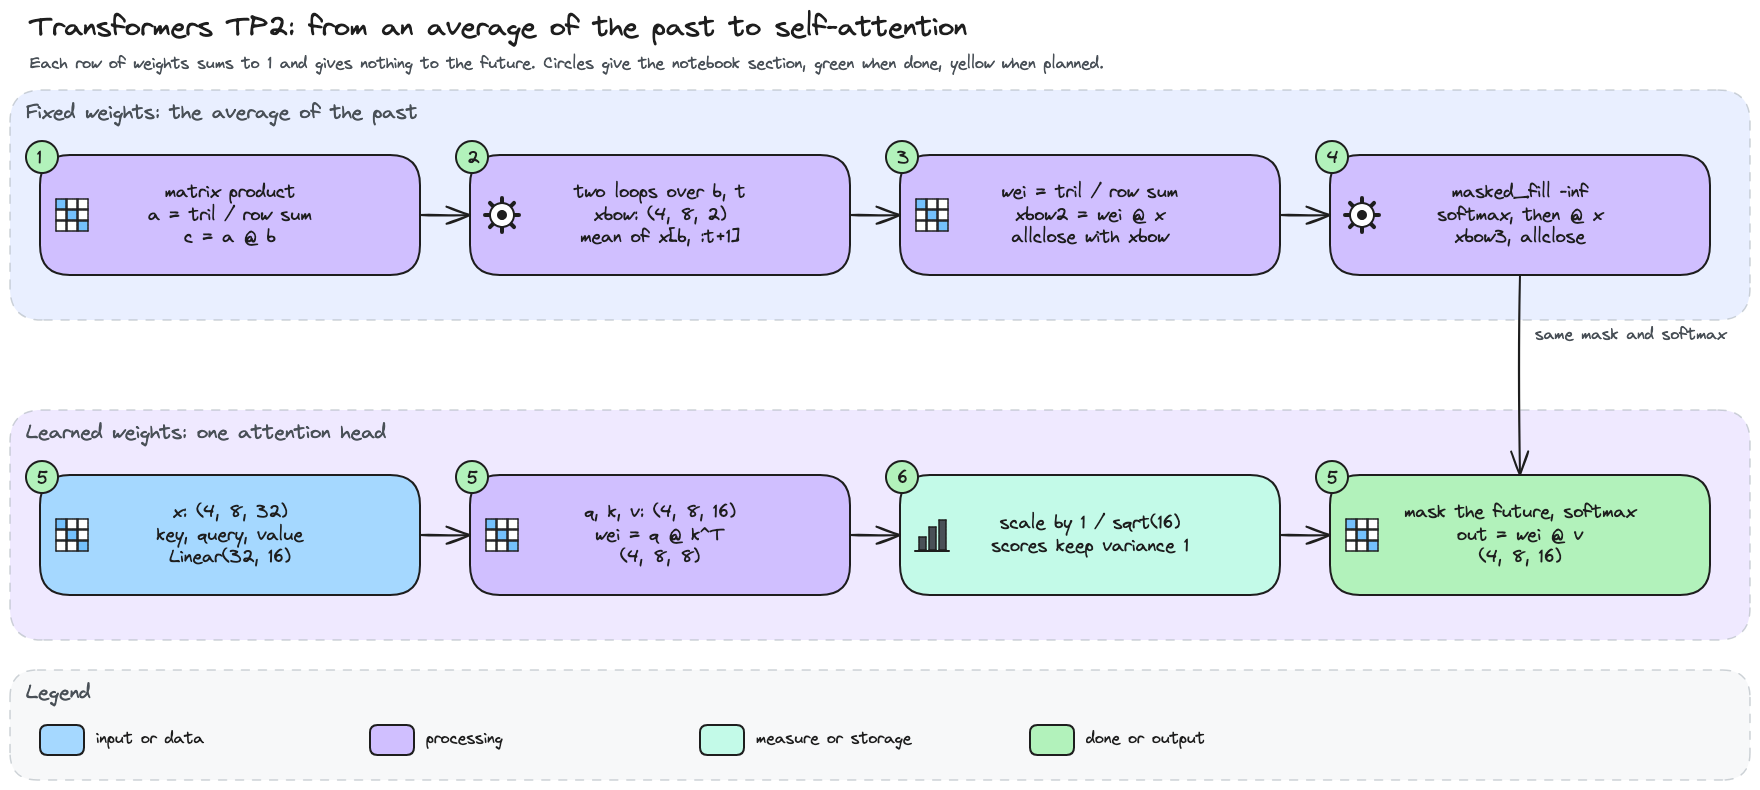

In [1]:
# Workflow diagram: from a fixed average of the past to one attention head (diagrams/transformers/).
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp2_workflow.png', width=900))

## 0. My problem and what I carry over

I want each position of a sequence to collect information from the positions before it, and never from those after. I start from what TP1 taught me, and the diagram links each lesson to what it changes here.

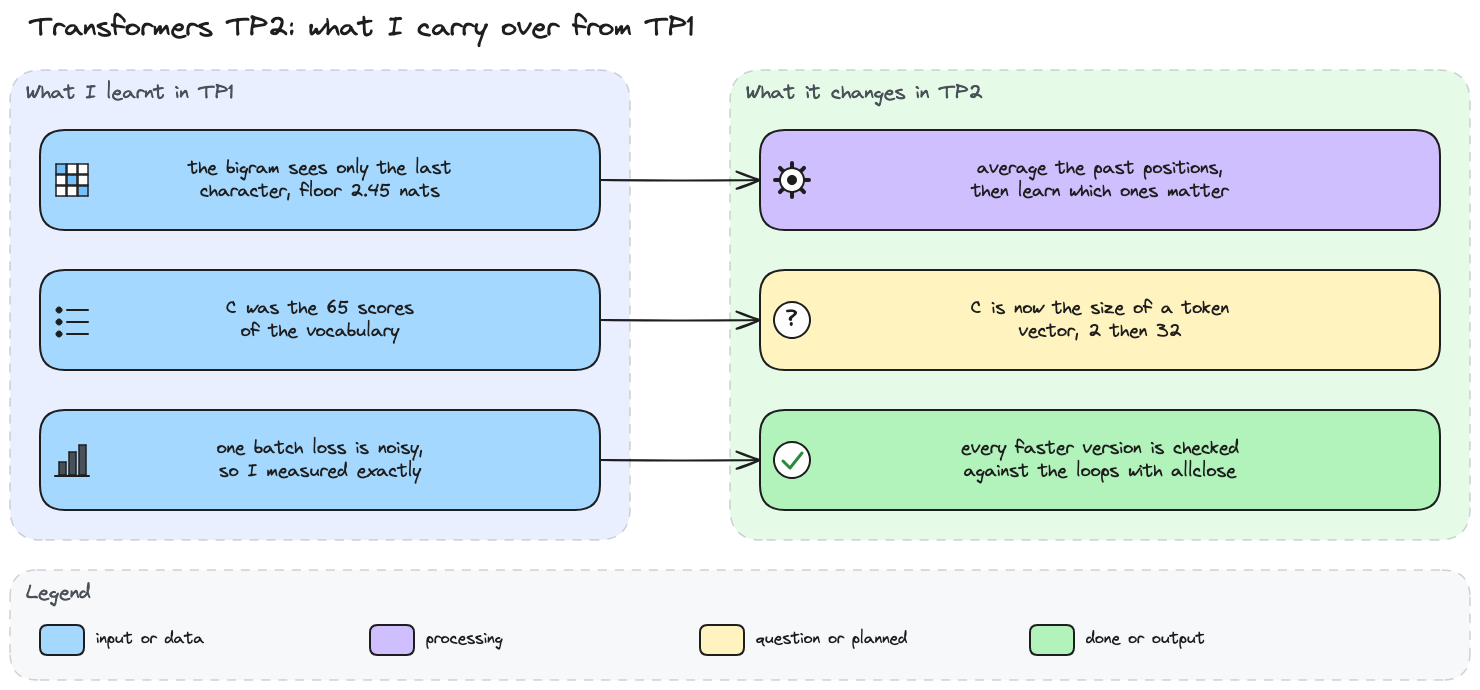

In [2]:
# What I carry over from TP1 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp2_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - A lower-triangular matrix with rows summing to 1 gives exactly the averages of my loops, because both compute the same weighted sum. Sections 2 and 3 check it with `torch.allclose`.
> - Filling the future with −∞ and applying softmax gives the same weights, since exp(−∞) = 0 and softmax divides by the row sum. Section 4 tests it.
> - With random keys and queries, the attention weights are no longer uniform, but each row still sums to 1 and gives nothing to the future. I look at it in section 5.
> - Without scaling, the variance of q·kᵀ grows with the head size, so softmax puts almost all the weight on one token. Section 6 measures this.

### My environment

I use the project's `.venv/bin/python` as kernel, with the same dependencies as in TP1.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I keep every tensor on the CPU in this TP, because they are tiny and nothing is trained. I fix seed 42 once, and the handout cells also set their own seeds, so every random draw is the same at every run.

In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the handout cells set their own seeds too.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: CPU, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: CPU, seed: 42


## 1. Aggregate with a matrix product

Before any attention, I want to check that one row of a matrix can pick several vectors and weight them. A lower-triangular matrix whose rows sum to 1 should turn a matrix product into an average of the rows above. The diagram shows the small example and what I check.

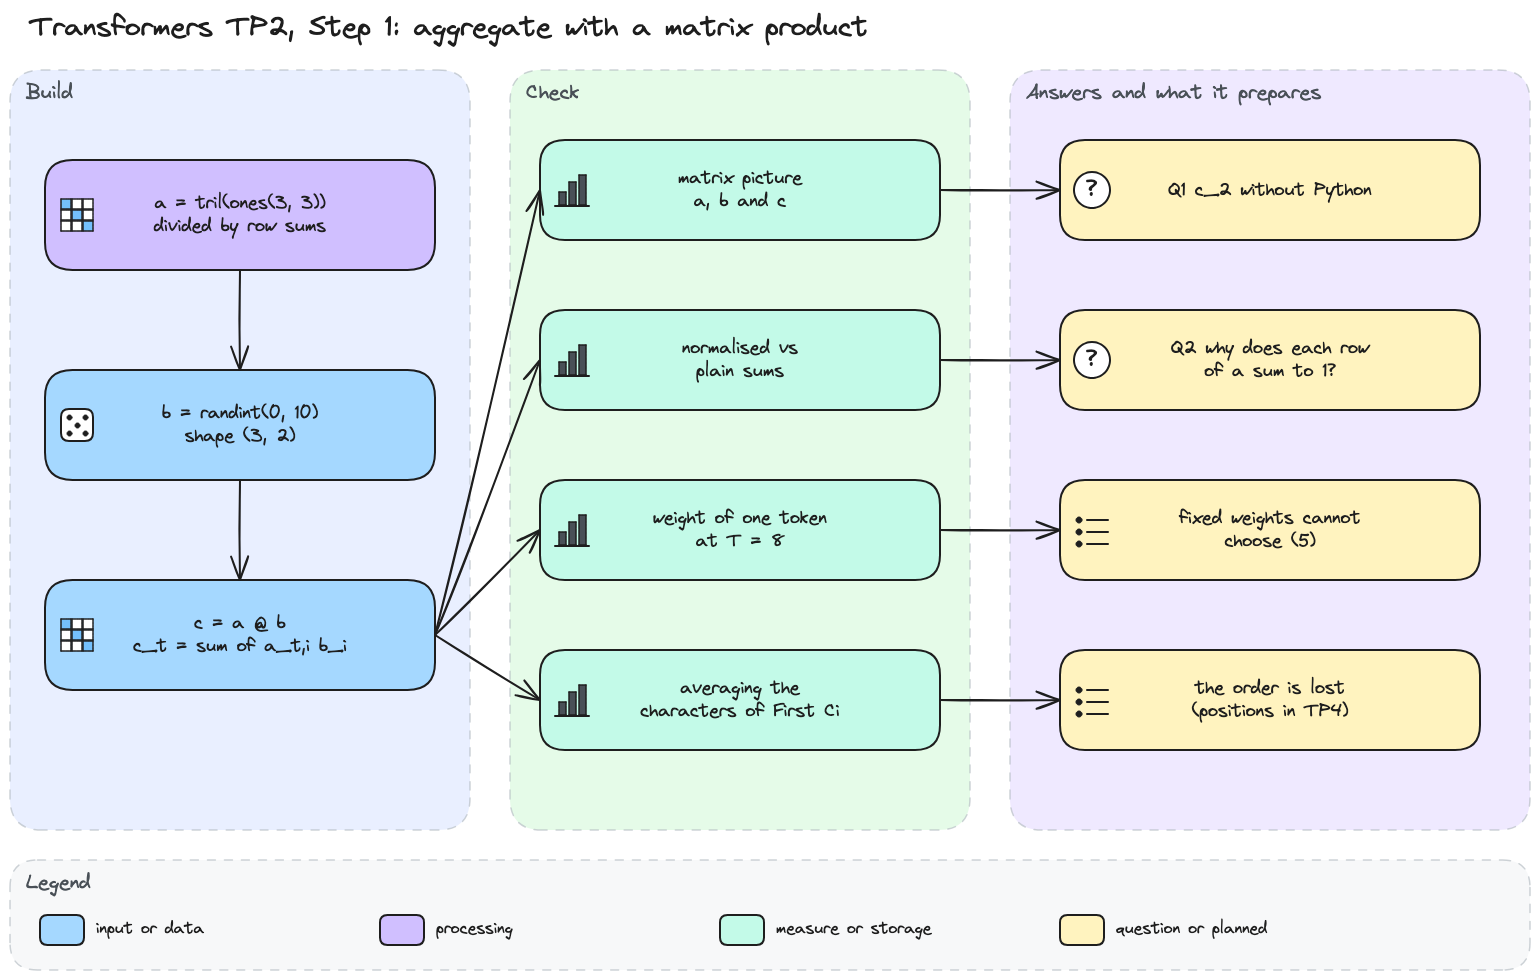

In [4]:
# Step 1 diagram: a, b and c, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step1.png', width=900))

In [5]:
# A lower-triangular matrix with rows summing to 1, a random matrix, and their product.
torch.manual_seed(42)

a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)

b = torch.randint(0, 10, (3, 2)).float()

c = a @ b

print(a)
print(b)
print(c)

tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


Row t of `a` puts the weight 1/(t+1) on the first t+1 positions and 0 after them, so `c = a @ b` should average the rows of `b`. What is c₂ without Python? I count rows from 1, as in the formula c_t = Σ a_t,i b_i. Row 2 of `a` is (1/2, 1/2, 0), so c₂ = ½ b₁ + ½ b₂ = ½ (2, 7) + ½ (6, 4) = (4, 5.5). The printed `c` agrees, on its row of index 1 in Python.

I draw the three matrices to see this choice row by row.

In [6]:
# Tools: draw a small matrix as a heatmap, with its values written in the cells.
import matplotlib.pyplot as plt


def show_matrix(ax: plt.Axes, matrix: torch.Tensor, title: str, digits: int = 2) -> None:
    """Heatmap of a 2D tensor with each value written in its cell."""
    values = matrix.detach().cpu()
    finite = values[values.isfinite()]
    low, high = finite.min().item(), finite.max().item()
    cmap = plt.get_cmap('Blues').copy()
    cmap.set_bad('#e9ecef')  # -inf cells in light grey
    shown = values.masked_fill(~values.isfinite(), float('nan'))
    ax.imshow(shown, cmap=cmap, vmin=low, vmax=high + 0.6 * (high - low or 1))  # light cells
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            ax.text(col, row, f'{values[row, col]:.{digits}f}', ha='center', va='center',
                    fontsize=9)
    ax.set_xticks(range(values.shape[1]))
    ax.set_yticks(range(values.shape[0]))
    ax.set_title(title, fontsize=10)

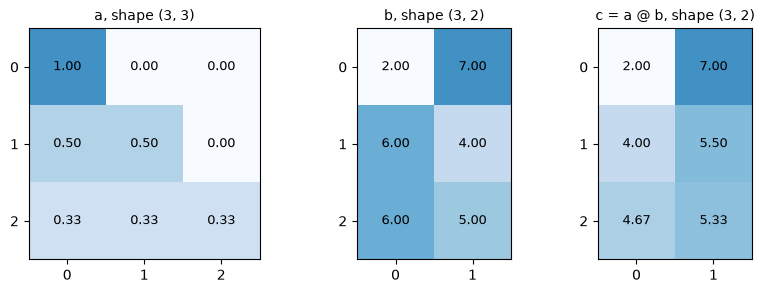

In [7]:
# How does a row of a pick the rows of b? The three matrices with their values.
fig, axes = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [3, 2, 2]})
for ax, matrix, title in ((axes[0], a, 'a, shape (3, 3)'), (axes[1], b, 'b, shape (3, 2)'),
                          (axes[2], c, 'c = a @ b, shape (3, 2)')):
    show_matrix(ax, matrix, title)
plt.show()

Each row of `a` lights up the rows of `b` it uses. The first row of `c` copies the first row of `b`, (2, 7), the second averages two rows into (4, 5.5), and the last averages all three into (4.67, 5.33). So a matrix product can pick vectors and weight them, which is all that averaging the past needs.

The rows of `a` were divided by their sum, and I want to see what that division changes.

Row sums of a: [1.0, 1.0, 1.0]
c, rows summing to 1: [[2.0, 7.0], [4.0, 5.5], [4.67, 5.33]]
Same product without the division: [[2.0, 7.0], [8.0, 11.0], [14.0, 16.0]]
Range of b per column: from [2.0, 4.0] to [6.0, 7.0]


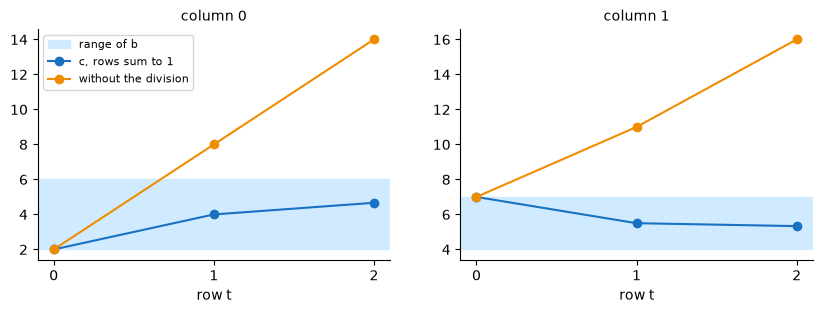

In [8]:
# Why should each row of a sum to 1? Row sums, then the same product without the division.
plain = torch.tril(torch.ones(3, 3)) @ b
rounded = lambda matrix: [[round(value, 2) for value in row] for row in matrix.tolist()]
print(f'Row sums of a: {a.sum(1).tolist()}')
print(f'c, rows summing to 1: {rounded(c)}')
print(f'Same product without the division: {rounded(plain)}')
print(f'Range of b per column: from {b.min(0).values.tolist()} to {b.max(0).values.tolist()}')

rows = torch.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for col, ax in enumerate(axes):
    ax.axhspan(b[:, col].min(), b[:, col].max(), color='#d0ebff', label='range of b')
    ax.plot(rows, c[:, col], marker='o', color='#1971c2', label='c, rows sum to 1')
    ax.plot(rows, plain[:, col], marker='o', color='#f08c00', label='without the division')
    ax.set_xticks(rows)
    ax.set_xlabel('row t')
    ax.set_title(f'column {col}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

Why does each row of `a` sum to 1? Because each row was divided by the number of ones it holds, so the weights of a row form an average. Then `c` stays inside the range of `b`, between 2 and 6 in the first column and between 4 and 7 in the second. Without the division, the product gives running sums, (2, 7), then (8, 11), then (14, 16), which grow with t. A later position would get a bigger vector only because more tokens come before it.

With rows summing to 1, I now look at how much one past token weighs when the context grows.

Weight of the first token in each row: [1.0, 0.5, 0.333, 0.25, 0.2, 0.167, 0.143, 0.125]


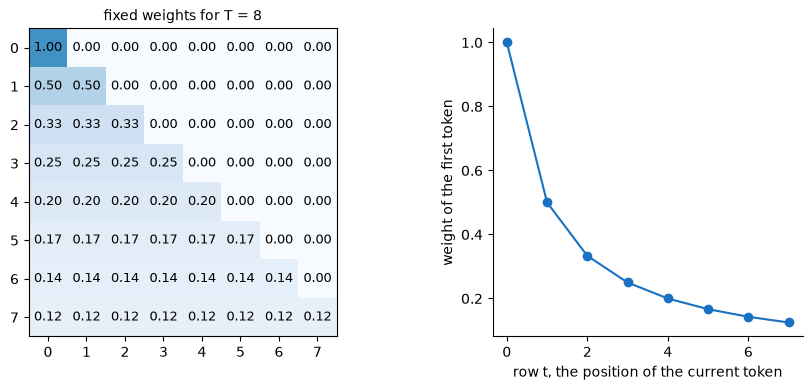

In [9]:
# With fixed weights, how much does one past token count as the context grows? T = 8.
T = 8
weights = torch.tril(torch.ones(T, T))
weights = weights / weights.sum(1, keepdim=True)
print(f'Weight of the first token in each row: {[round(w, 3) for w in weights[:, 0].tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [3, 2]})
show_matrix(axes[0], weights, 'fixed weights for T = 8')
axes[1].plot(range(T), weights[:, 0], marker='o', color='#1971c2')
axes[1].set_xlabel('row t, the position of the current token')
axes[1].set_ylabel('weight of the first token')
axes[1].spines[['top', 'right']].set_visible(False)
plt.show()

In each row, every visible token gets the same weight 1/(t+1), so the first token weighs 1, then 0.5, and only 0.125 in the last row. This weight depends only on the position, never on what the token contains. Fixed weights cannot decide that one past character matters more than another, and that is what the learned attention weights of section 5 will do.

To see what an average keeps from real text, I apply these weights to the first characters of the corpus.

Characters of the snippet: [' ', 'C', 'F', 'i', 'r', 's', 't']
Last row, share of each character: [0.125, 0.125, 0.125, 0.25, 0.125, 0.125, 0.125]
Same last row for the reversed snippet: True


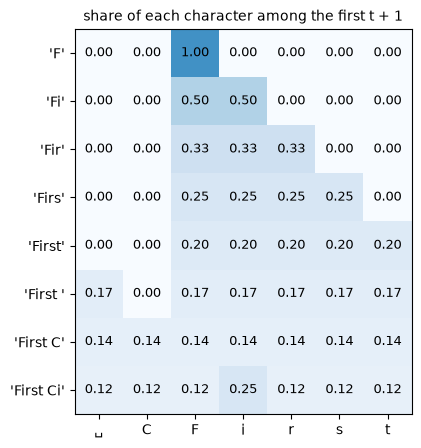

In [10]:
# What does an average of the past keep from real text? One-hot vectors of "First Ci", averaged.
snippet = "First Ci"
symbols = sorted(set(snippet))
one_hot = torch.zeros(len(snippet), len(symbols))
one_hot[torch.arange(len(snippet)), torch.tensor([symbols.index(ch) for ch in snippet])] = 1
averaged = weights @ one_hot
reversed_last = (weights @ one_hot.flip(0))[-1]  # the same characters in reverse order

print(f'Characters of the snippet: {symbols}')
print(f'Last row, share of each character: {[round(v, 3) for v in averaged[-1].tolist()]}')
print(f'Same last row for the reversed snippet: {torch.allclose(averaged[-1], reversed_last)}')

fig, ax = plt.subplots(figsize=(7, 5))
show_matrix(ax, averaged, 'share of each character among the first t + 1')
ax.set_xticks(range(len(symbols)), ['␣' if ch == ' ' else ch for ch in symbols])
ax.set_yticks(range(len(snippet)), [repr(snippet[:t + 1]) for t in range(len(snippet))])
plt.show()

Each row now gives the share of each character among the first t+1. In the last row, `i` has 0.25 because it appears twice in `First Ci`, and every other character has 0.125. So an average keeps which characters appeared and how often. It loses their order, since the reversed snippet gives the same last row. A model built only on averages could not tell `First` from `tsriF`, which is why TP4 adds the position of each token.

> *My conclusion:*
>
> A lower-triangular matrix whose rows sum to 1 turns a matrix product into an average of the rows above, so one product averages the whole past at once. The division keeps the result inside the range of the vectors, but the weights stay fixed at 1/(t+1) and the average forgets the order. Section 2 builds the same average with loops, as a reference for the faster versions.
>
> My answers to the two questions of this step:
>
> 1. c₂ = ½ b₁ + ½ b₂ = ½ (2, 7) + ½ (6, 4) = (4, 5.5).
> 2. Each row of `a` sums to 1 because it is divided by its number of ones, so every output is an average of the rows of `b` and keeps their scale.

## 2. Average only the past

For each sequence of the batch and each position t, I want the mean of all the tokens visible up to t, and none after. I write it first with two loops, slow but easy to check, so it becomes my reference for the faster versions. The diagram shows the loops and what I check.

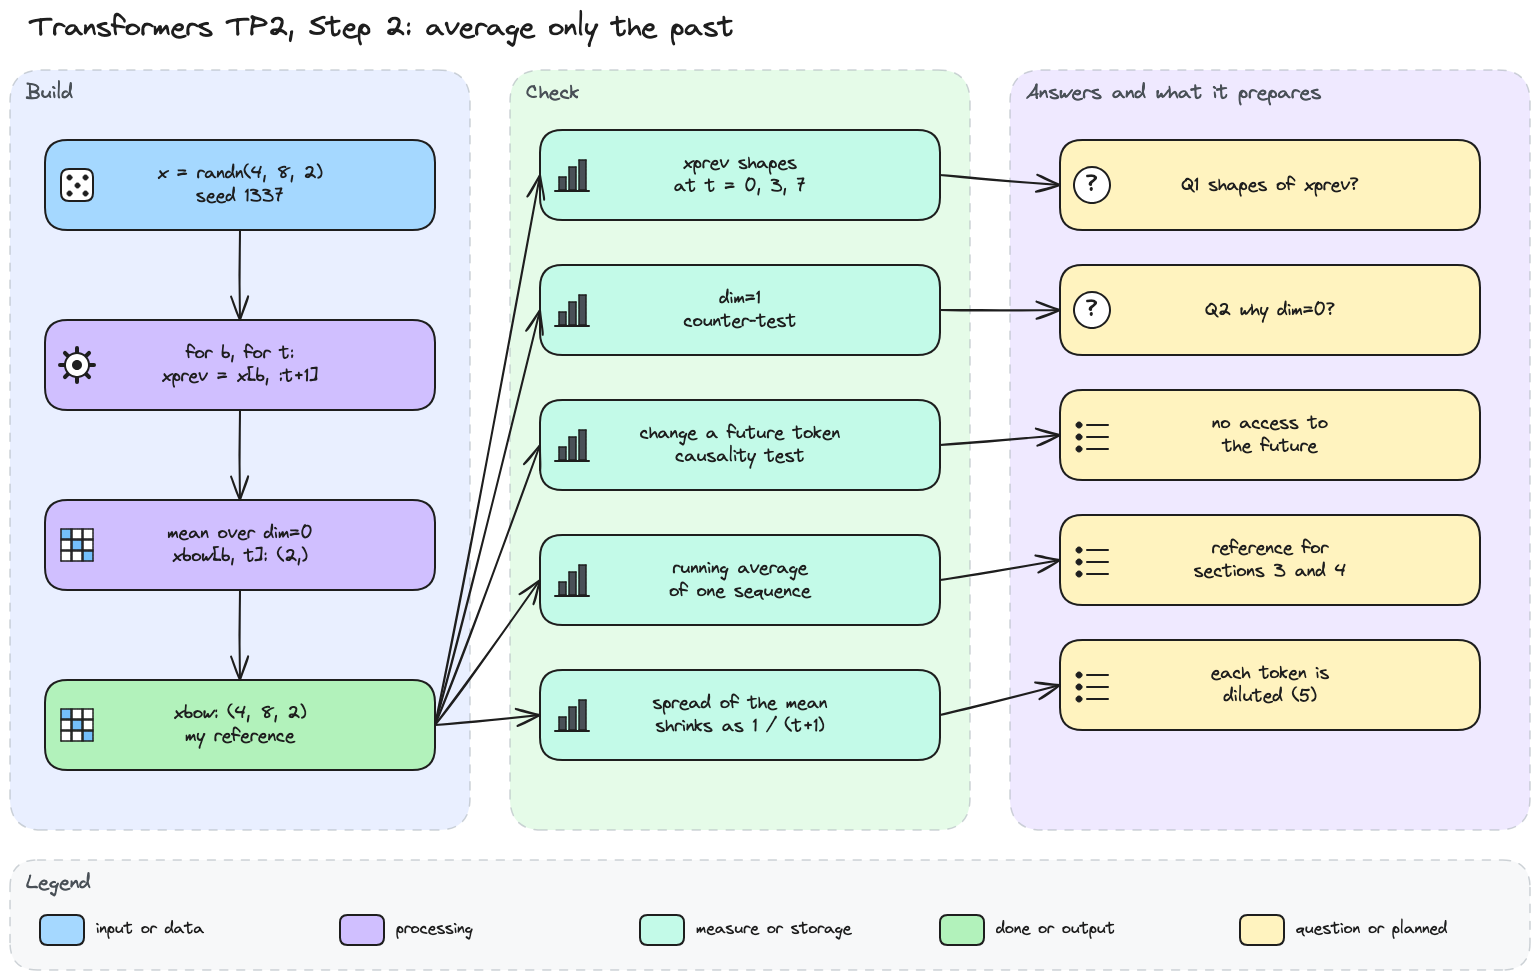

In [11]:
# Step 2 diagram: the two loops, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step2.png', width=900))

In [12]:
# The causal mean with two loops: for each sequence b and position t, the mean of x[b, :t+1].
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t + 1]  # (t+1, C)
        xbow[b, t] = torch.mean(xprev, dim=0)

print(f'x: {tuple(x.shape)}, xbow: {tuple(xbow.shape)}')
for t in (0, 3, 7):
    print(f'xprev for t = {t}: {tuple(x[0, :t + 1].shape)}')

x: (4, 8, 2), xbow: (4, 8, 2)
xprev for t = 0: (1, 2)
xprev for t = 3: (4, 2)
xprev for t = 7: (8, 2)


What shape does `xprev` have? (1, 2) at t = 0, (4, 2) at t = 3 and (8, 2) at t = 7, so t+1 rows of C = 2 channels. Each row is one visible token, so `xprev` grows by one row at each position, while `xbow` keeps the shape of `x`, (4, 8, 2). Why the mean over dim=0? Because dim=0 runs over these rows, the positions, so the mean mixes tokens and keeps the 2 channels apart.

I check what the other axis would do.

In [13]:
# What would dim=1 do? At t = 3, the mean over the channels instead of the positions.
xprev = x[0, :4]
print(f'Mean over dim=0: {tuple(xprev.mean(dim=0).shape)}, '
      f'over dim=1: {tuple(xprev.mean(dim=1).shape)}')
try:
    xbow.clone()[0, 3] = xprev.mean(dim=1)  # on a copy, so xbow stays intact
except RuntimeError as error:
    print(f'Writing it into xbow[0, 3] fails: {error}')

Mean over dim=0: (2,), over dim=1: (4,)
Writing it into xbow[0, 3] fails: The expanded size of the tensor (2) must match the existing size (4) at non-singleton dimension 0.  Target sizes: [2].  Tensor sizes: [4]


Over dim=1, the mean averages the 2 channels of each token instead, and gives 4 numbers, one per position. These numbers mix two different features of a token, and they do not fit the slot `xbow[0, 3]`, which expects 2 values, so PyTorch refuses the copy. dim=0 is the only axis that averages tokens and keeps each channel on its own.

To run the loops on other inputs, I wrap them in a function.

In [14]:
# Tools: the same two loops as a function, to run them on other inputs.
def loop_mean(x: torch.Tensor) -> torch.Tensor:
    """Causal mean with two loops: row t of each sequence is the mean of its rows 0 to t."""
    B, T, C = x.shape
    out = torch.zeros((B, T, C))
    for b in range(B):
        for t in range(T):
            out[b, t] = torch.mean(x[b, :t + 1], dim=0)
    return out


print(f'loop_mean(x) gives xbow again: {torch.equal(loop_mean(x), xbow)}')

loop_mean(x) gives xbow again: True


In [15]:
# Does a position ever read the future? Token 5 of the first sequence raised by 10, loops again.
changed = x.clone()
changed[0, 5] += 10
changed_bow = loop_mean(changed)

moves = (changed_bow[0] - xbow[0]).abs().max(dim=1).values
print(f'Largest change in each row of xbow[0]: {[round(v, 3) for v in moves.tolist()]}')
print(f'Rows 0 to 4 unchanged: {torch.equal(changed_bow[0, :5], xbow[0, :5])}')
print(f'Other sequences unchanged: {torch.equal(changed_bow[1:], xbow[1:])}')

Largest change in each row of xbow[0]: [0.0, 0.0, 0.0, 0.0, 0.0, 1.667, 1.429, 1.25]
Rows 0 to 4 unchanged: True
Other sequences unchanged: True


Raising token 5 changes nothing in rows 0 to 4, so no earlier position reads it, and the other sequences of the batch do not move either. Rows 5, 6 and 7 move by 1.667, 1.429 and 1.25, which is 10/6, 10/7 and 10/8. A token weighs 1/(t+1) in the mean at position t, as in section 1, so its influence fades as the past grows.

Next I look at what the running mean does to one sequence.

x[0], channel 0: [0.18, -0.36, 0.63, 0.95, 0.36, -1.35, 0.24, -0.92]
xbow[0], channel 0: [0.18, -0.09, 0.15, 0.35, 0.35, 0.07, 0.09, -0.03]


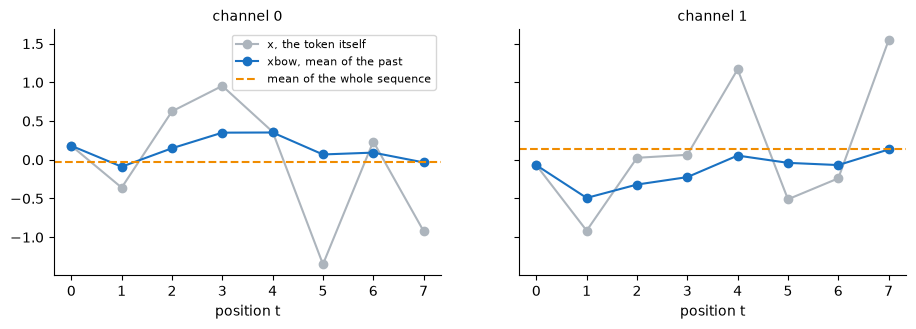

In [16]:
# What does the running mean look like? Both channels of the first sequence, x against xbow.
print(f'x[0], channel 0: {[round(v, 2) for v in x[0, :, 0].tolist()]}')
print(f'xbow[0], channel 0: {[round(v, 2) for v in xbow[0, :, 0].tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for channel, ax in enumerate(axes):
    ax.plot(range(T), x[0, :, channel], marker='o', color='#adb5bd', label='x, the token itself')
    ax.plot(range(T), xbow[0, :, channel], marker='o', color='#1971c2',
            label='xbow, mean of the past')
    ax.axhline(x[0, :, channel].mean(), color='#f08c00', linestyle='--',
               label='mean of the whole sequence')
    ax.set_xlabel('position t')
    ax.set_title(f'channel {channel}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

The first value of `xbow` copies the first token, 0.18 in channel 0, and then the mean follows the next tokens less and less. In channel 0, token 5 drops to -1.35 but the mean only goes from 0.35 to 0.07. At position 7 the mean is -0.03, exactly the mean of the whole sequence, since it averages all 8 tokens. The early positions know few tokens but see them clearly, while the last ones know every token a little.

I measure this dilution on many random sequences.

Position 0: variance 1.002, 1 / (t+1) = 1.000
Position 1: variance 0.501, 1 / (t+1) = 0.500
Position 3: variance 0.237, 1 / (t+1) = 0.250
Position 7: variance 0.124, 1 / (t+1) = 0.125


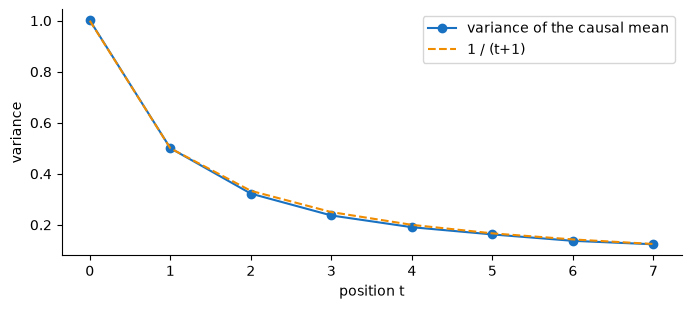

In [17]:
# How much of one token survives in the mean? Variance of the causal mean of many random sequences.
torch.manual_seed(RANDOM_STATE)
many = torch.randn(2000, T, C)
variance = loop_mean(many).var(dim=(0, 2))
for t in (0, 1, 3, 7):
    print(f'Position {t}: variance {variance[t]:.3f}, 1 / (t+1) = {1 / (t + 1):.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(T), variance, marker='o', color='#1971c2', label='variance of the causal mean')
ax.plot(range(T), [1 / (t + 1) for t in range(T)], linestyle='--', color='#f08c00',
        label='1 / (t+1)')
ax.set_xlabel('position t')
ax.set_ylabel('variance')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The variance of the causal mean follows 1/(t+1) closely, with 1.002 at position 0, 0.501 at position 1, 0.237 at position 3 and 0.124 at position 7. Averaging t+1 independent tokens divides their variance by t+1, so at position 7 each token keeps only an eighth of its weight. In NLP TP2 I averaged all the token vectors of a reply in the same way, with a masked mean that ignored the padding (section 2.2). Here the mean only covers the past, but it dilutes the tokens just as much. Fixed weights cannot keep an important token loud, and the learned weights of section 5 are meant to do that.

> *My conclusion:*
>
> The two loops give, for every sequence and position, the mean of the tokens up to that position, and changing a future token leaves the past untouched. The mean follows each sequence less and less, and its variance falls like 1/(t+1), so every token is diluted as the context grows. These loops are slow but simple, so `xbow` becomes my reference for the vectorised versions of sections 3 and 4.
>
> My answers to the two questions of this step:
>
> 1. `xprev` has shape (1, 2) at t = 0, (4, 2) at t = 3 and (8, 2) at t = 7, so (t+1, C).
> 2. The mean is over dim=0 because the rows of `xprev` are the positions, so it averages the tokens and keeps the C channels apart. Over dim=1 it would average the channels instead.

## 3. Vectorise with a triangular matrix

The loops of section 2 compute the B × T means one by one. Section 1 showed that one product with a lower-triangular matrix can do the same averaging, so I build that matrix at size T and compare the result with `xbow`. The diagram shows the product and what I check.

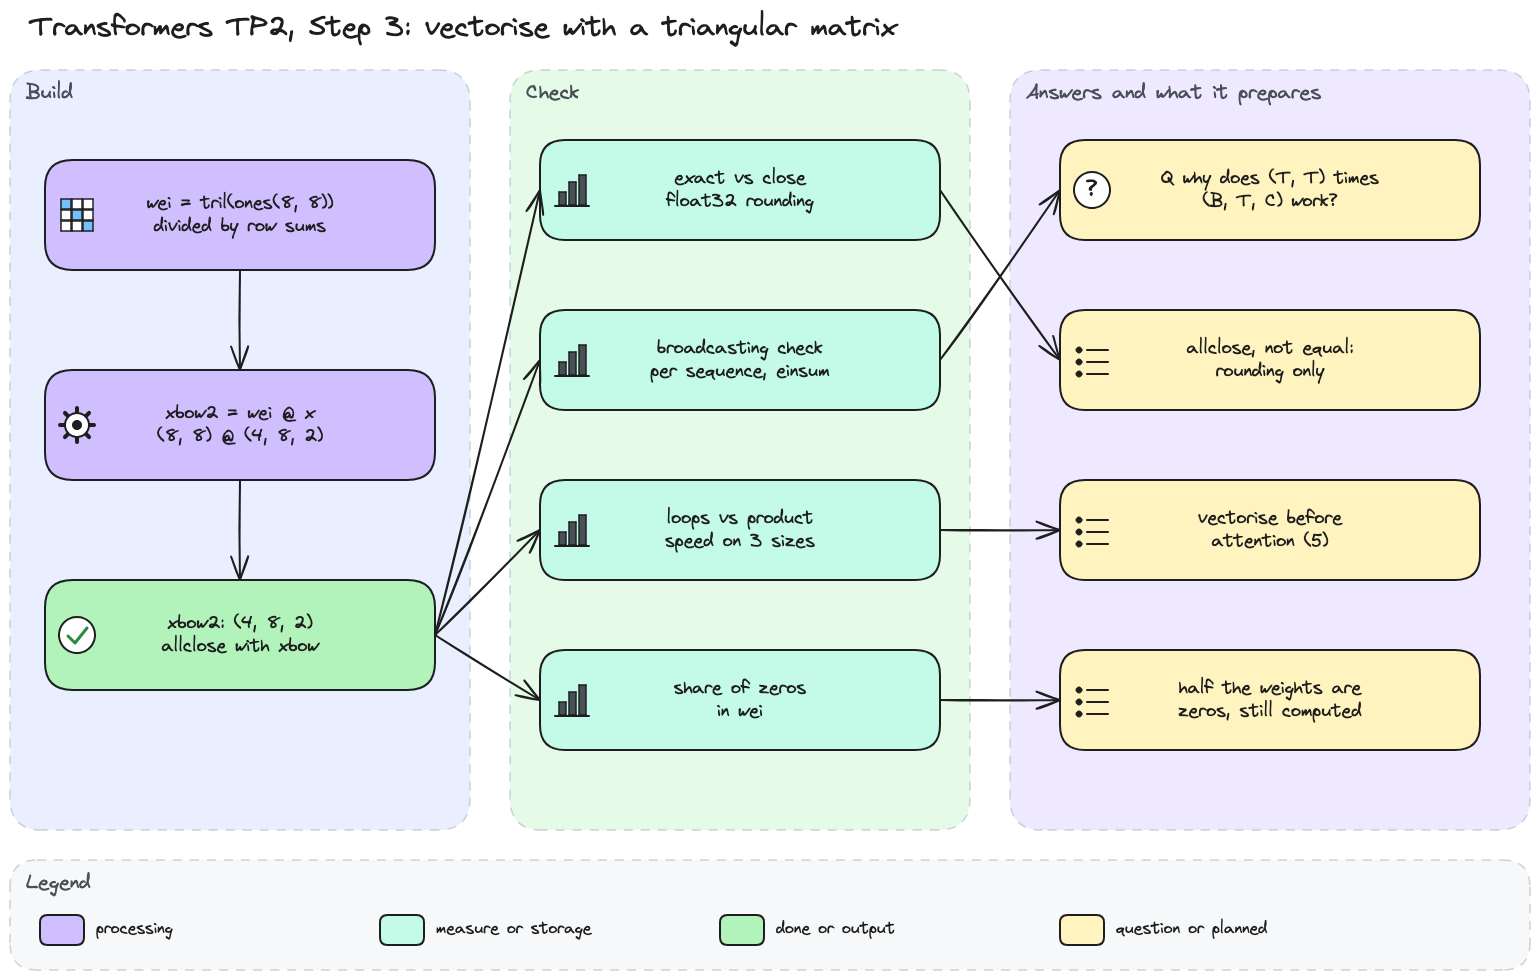

In [18]:
# Step 3 diagram: the triangular product, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp2_step3.png', width=900))

In [19]:
# The same causal mean in one matrix product, checked against the loops of section 2.
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x
print(torch.allclose(
    xbow, xbow2, atol=1e-6
))

print(f'wei: {tuple(wei.shape)}, x: {tuple(x.shape)}, xbow2: {tuple(xbow2.shape)}')
print(f'Same matrix as the weights of section 1: {torch.equal(wei, weights)}')

True
wei: (8, 8), x: (4, 8, 2), xbow2: (4, 8, 2)
Same matrix as the weights of section 1: True


The check prints True, so one product gives the same causal means as the loops, and my hypothesis on the triangular matrix holds. `wei` is the same 8 × 8 matrix as in section 1, and multiplying it with `x` of shape (4, 8, 2) gives `xbow2` of shape (4, 8, 2), like `xbow`. The check uses `torch.allclose` with a tolerance, though, so I want to know whether the two results are exactly equal.

In [20]:
# Exactly equal, or only close? The largest gap between the loops and the product.
print(f'torch.equal(xbow, xbow2): {torch.equal(xbow, xbow2)}')
print(f'Largest difference: {(xbow - xbow2).abs().max().item():.2e}')
print(f'Machine epsilon of float32: {torch.finfo(torch.float32).eps:.2e}')

torch.equal(xbow, xbow2): False
Largest difference: 1.19e-07
Machine epsilon of float32: 1.19e-07


They are not exactly equal, and the largest gap is 1.19e-07, the machine epsilon of float32. The loops sum the past tokens and then divide, while the product multiplies each token by its weight and then sums, so the same numbers are rounded in a different order. A gap of one epsilon is rounding and nothing more. The tolerance of 1e-6 accepts it, but a real mistake, such as a wrong weight, would move the result far more and still fail the check.

The product mixes a (T, T) matrix with a (B, T, C) tensor, and I check how PyTorch pairs them.

In [21]:
# Why does a (T, T) matrix multiply a (B, T, C) tensor? The same product, written three other ways.
per_sequence = torch.stack([wei @ x[b] for b in range(B)])
explicit = torch.einsum('tu,buc->btc', wei, x)  # sum over the past positions u, for every b and c
expanded = wei.expand(B, T, T) @ x

print(f'wei @ x[b] for each sequence, stacked: {torch.equal(per_sequence, xbow2)}')
print(f'einsum over the positions: {torch.equal(explicit, xbow2)}')
print(f'wei expanded to {tuple(wei.expand(B, T, T).shape)}: {torch.equal(expanded, xbow2)}')

wei @ x[b] for each sequence, stacked: True
einsum over the positions: True
wei expanded to (4, 8, 8): True


Why does `wei @ x` work with a (T, T) matrix and a (B, T, C) tensor? PyTorch reads the first dimension of `x` as a batch and repeats `wei` for each sequence, as if it had shape (4, 8, 8). Each sequence then gets the product (T, T) @ (T, C) → (T, C) with the same weights. The three checks print True, since stacking `wei @ x[b]` sequence by sequence, expanding `wei` to (4, 8, 8), and the einsum that sums over the past positions u all give `xbow2` exactly. So the product does in one call what the loops did, for every sequence and channel at once.

Next I measure what this saves in time.

B, T, C = (4, 8, 2): 32 means, loops 0.144 ms, product 0.0023 ms, 63 times faster
B, T, C = (32, 64, 32): 2,048 means, loops 7.980 ms, product 0.0386 ms, 207 times faster
B, T, C = (64, 256, 64): 16,384 means, loops 65.729 ms, product 0.6339 ms, 104 times faster


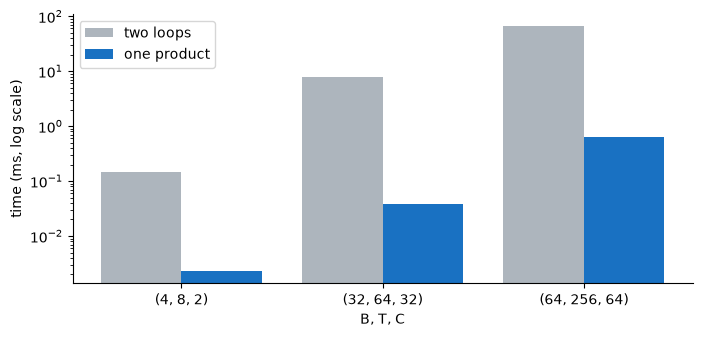

In [22]:
# Is the product worth it? Best of 3 timings for the loops and for the product, on three sizes.
import timeit

SIZES = [(4, 8, 2), (32, 64, 32), (64, 256, 64)]
timings = {}
for size in SIZES:
    sample = torch.randn(size)
    causal = torch.tril(torch.ones(size[1], size[1]))
    causal = causal / causal.sum(1, keepdim=True)
    loops = min(timeit.repeat(lambda: loop_mean(sample), number=1, repeat=3))
    product = min(timeit.repeat(lambda: causal @ sample, number=10, repeat=3)) / 10
    timings[size] = (loops * 1e3, product * 1e3)
    print(f'B, T, C = {size}: {size[0] * size[1]:,} means, loops {loops * 1e3:.3f} ms, '
          f'product {product * 1e3:.4f} ms, {loops / product:.0f} times faster')

labels = [str(size) for size in SIZES]
positions = torch.arange(len(SIZES))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(positions - 0.2, [loops for loops, _ in timings.values()], 0.4, color='#adb5bd',
       label='two loops')
ax.bar(positions + 0.2, [product for _, product in timings.values()], 0.4, color='#1971c2',
       label='one product')
ax.set_xticks(positions, labels)
ax.set_yscale('log')
ax.set_xlabel('B, T, C')
ax.set_ylabel('time (ms, log scale)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

At every size the product is much faster, by the factors printed above, which range from tens to hundreds. The loops compute one mean at a time, 32 at the smallest size and 16,384 at the largest, so their time grows with B × T. The product hands the whole computation to one optimised matrix routine. The exact factors change a little from one run to the next, since they depend on the machine, but the order of magnitude stays. Attention will compute this kind of product at every layer, so the loops are only useful as a reference.

The product is fast, but it also multiplies a lot of zeros.

In [23]:
# How much of wei is zero? The product still multiplies by every one of them.
print(f'Zeros in wei: {(wei == 0).sum().item()} of {wei.numel()}')
for size in (8, 64, 256):
    zeros = size * (size - 1) // 2
    print(f'T = {size}: {zeros:,} zeros of {size * size:,} weights, {100 * zeros / size**2:.2f}%')

Zeros in wei: 28 of 64
T = 8: 28 zeros of 64 weights, 43.75%
T = 64: 2,016 zeros of 4,096 weights, 49.22%
T = 256: 32,640 zeros of 65,536 weights, 49.80%


`wei` holds 28 zeros out of 64, 43.75%, all above the diagonal where the future would be. The share tends to one half as T grows, with 49.22% at T = 64 and 49.80% at T = 256. The product still multiplies by each of these zeros, so almost half of its work goes to positions the causal rule already forbids. That is the price of computing every position in one product, and attention will pay it too, since its scores also form a (T, T) matrix.

> *My conclusion:*
>
> The triangular product gives the same causal means as the loops, up to the rounding of float32, and it is tens of times faster. PyTorch shares the (T, T) weights across the B sequences, so one call averages every sequence and channel. Almost half of the weights are zeros, which costs work but keeps the code a single product. Section 4 builds the same weights with a mask and softmax, the form attention will use.
>
> My answer to the question of this step:
>
> - `wei @ x` works because PyTorch treats the first dimension of `x` as a batch and broadcasts the (T, T) matrix to (B, T, T). Each sequence then gets (T, T) @ (T, C) → (T, C) with the same weights.

## 4. The same weights from a mask and softmax

Section 3 wrote the weights directly as 1/(t+1). Here I build them in two moves, a mask that puts −∞ on the future and then softmax, because section 5 will put learned scores where the zeros are now. The diagram shows the moves and what I check.

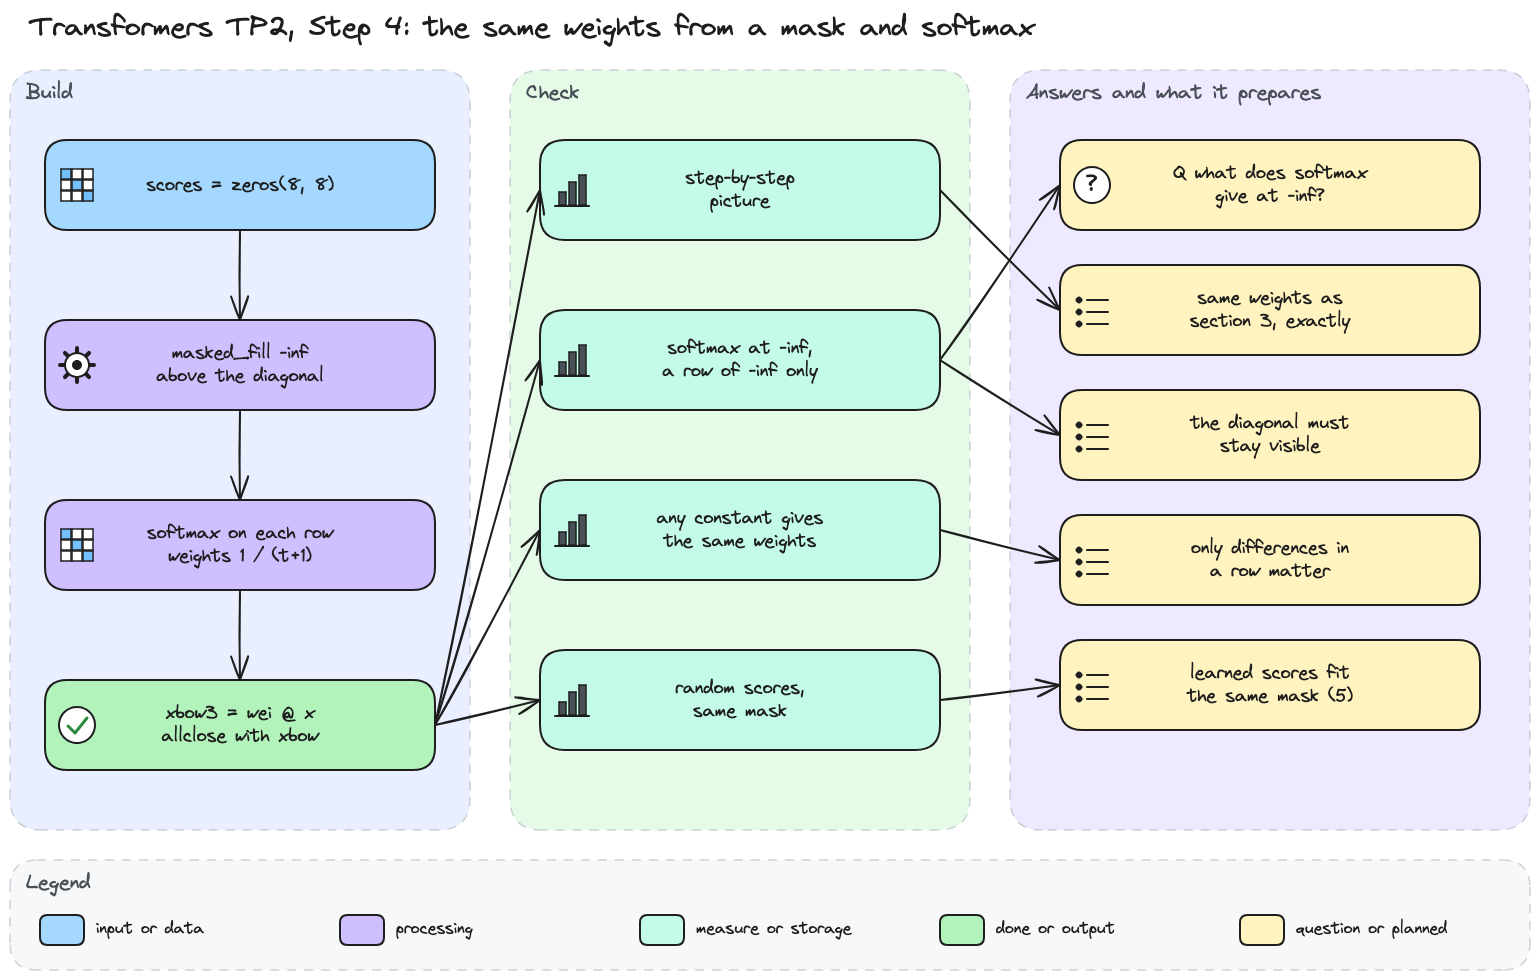

In [24]:
# Step 4 diagram: zeros, mask, softmax, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp2_step4.png', width=900))

In [25]:
# The same weights from a mask and softmax: zeros, -inf on the future, then softmax on each row.
import torch.nn.functional as F

tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

xbow3 = wei @ x
print(torch.allclose(
    xbow, xbow3, atol=1e-6
))

print(f'Exactly the weights of section 3: {torch.equal(wei, weights)}')

True
Exactly the weights of section 3: True


The check prints True, and the weights are not only close but exactly those of section 3. So a mask of −∞ followed by softmax rebuilds the uniform average of the past, and my hypothesis on the mask holds. I look at what each move does to the matrix.

Row sums after softmax: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0000001192092896, 1.0]


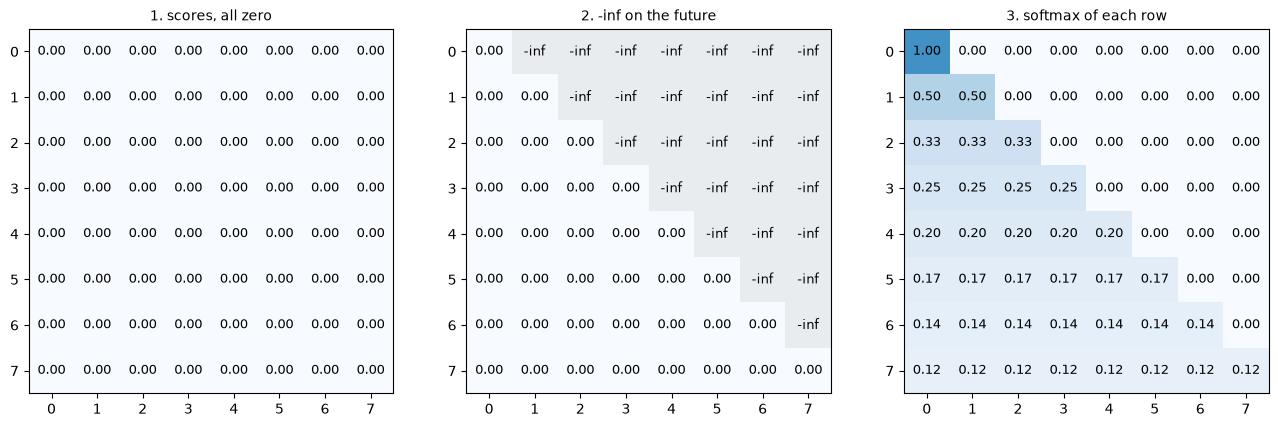

In [26]:
# What happens at each move? The scores at zero, the masked scores, then the weights after softmax.
scores = torch.zeros((T, T))
masked = scores.masked_fill(tril == 0, float('-inf'))
print(f'Row sums after softmax: {wei.sum(dim=1).tolist()}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, matrix, title in ((axes[0], scores, '1. scores, all zero'),
                          (axes[1], masked, '2. -inf on the future'),
                          (axes[2], wei, '3. softmax of each row')):
    show_matrix(ax, matrix, title)
plt.show()

The scores start at zero everywhere. The mask puts −∞ only above the diagonal, where row t would look at a later position, and leaves the diagonal and the past at zero. Softmax then turns each row into equal weights over the visible positions, 1, then 0.50, down to 0.12 in the last row, the same pattern as section 1. Every row sums to 1, up to a rounding of 1.0000001 in row 6.

The −∞ cells become exact zeros, and I want to see why.

In [27]:
# What does softmax give where a score is -inf? A short row, then a row where everything is masked.
minus_inf = float('-inf')
print(f'exp(-inf) = {torch.exp(torch.tensor(minus_inf)).item()}')
print(f'softmax([0, 0, -inf]) = {F.softmax(torch.tensor([0.0, 0.0, minus_inf]), dim=-1).tolist()}')
print(f'softmax([-inf, -inf, -inf]) = {F.softmax(torch.full((3,), minus_inf), dim=-1).tolist()}')

exp(-inf) = 0.0
softmax([0, 0, -inf]) = [0.5, 0.5, 0.0]
softmax([-inf, -inf, -inf]) = [nan, nan, nan]


What does softmax give where a score is −∞? A weight of exactly 0, since exp(−∞) = 0. In softmax([0, 0, −∞]) the last entry gets 0 and the two others share the whole weight, 0.5 each, because softmax divides by the sum of the visible exponentials only. A row where every score is −∞ gives NaN, because the division becomes 0/0. That is why `tril` keeps its diagonal, so every token always sees at least itself.

The scores were all zero, and I check whether that choice matters.

In [28]:
# Why zeros? Other constants through the same mask and softmax.
for value in (0.0, 5.0, -3.0):
    constant = F.softmax(torch.full((T, T), value).masked_fill(tril == 0, minus_inf), dim=-1)
    print(f'Scores all equal to {value}: same weights {torch.equal(constant, wei)}, '
          f'largest gap {(constant - wei).abs().max().item():.1e}')

Scores all equal to 0.0: same weights True, largest gap 0.0e+00
Scores all equal to 5.0: same weights True, largest gap 0.0e+00
Scores all equal to -3.0: same weights True, largest gap 0.0e+00


Scores all equal to 0, 5 or −3 give exactly the same weights, with a largest gap of 0. Softmax divides exp(z_i + c) by the sum of exp(z_j + c), so the constant c cancels out. Equal scores only mean that every visible token counts the same, whatever their value. What decides the weights is the difference between scores within a row, and that is what learned scores will provide.

I now give the same mask scores that are no longer equal.

Row sums: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
Everything above the diagonal is zero: True
Last row: [0.016, 0.066, 0.06, 0.125, 0.058, 0.403, 0.019, 0.254]


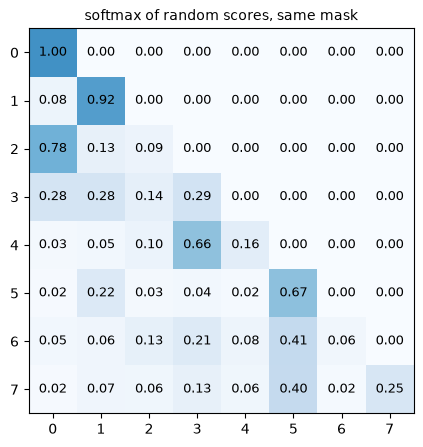

In [29]:
# What if the scores were not all equal? Random scores through the same mask and softmax.
torch.manual_seed(RANDOM_STATE)
random_wei = F.softmax(torch.randn(T, T).masked_fill(tril == 0, minus_inf), dim=-1)
print(f'Row sums: {[round(total, 3) for total in random_wei.sum(dim=1).tolist()]}')
print(f'Everything above the diagonal is zero: {(random_wei.triu(1) == 0).all().item()}')
print(f'Last row: {[round(weight, 3) for weight in random_wei[-1].tolist()]}')

fig, ax = plt.subplots(figsize=(6, 5))
show_matrix(ax, random_wei, 'softmax of random scores, same mask')
plt.show()

With random scores, every row still sums to 1 and every weight above the diagonal is still zero, so the invariant holds whatever the scores. The weights are no longer uniform, though. In the last row, token 5 takes 0.403 while token 0 gets only 0.016. The mask works like the one of my masked mean in NLP TP2 (section 2.2), which gave padding a weight of zero. Here it gives the future a weight of zero, even when a score would favour it. Section 5 replaces these random scores with scores computed from queries and keys.

> *My conclusion:*
>
> A mask of −∞ on the future followed by softmax gives exactly the weights of section 3. Softmax turns −∞ into a weight of zero and shares the whole row among the visible tokens, and only the differences between scores in a row matter. With unequal scores the same mask still keeps the invariant, which is the shape attention needs in section 5.
>
> My answer to the question of this step:
>
> - Where a score is −∞, softmax gives a weight of exactly 0, since exp(−∞) = 0. The other weights of the row are renormalised to sum to 1, and a row of −∞ only would give NaN.

## 5. Compute attention weights

Until now the weights of the past depended only on the position. Here each token computes a query, what it looks for, and a key, what it offers, and the match between them gives the scores that section 4 masked and normalised. My NLP TP2 ended with character-level attention as a next track, and this head is where it starts. The diagram shows the shapes and what I check.

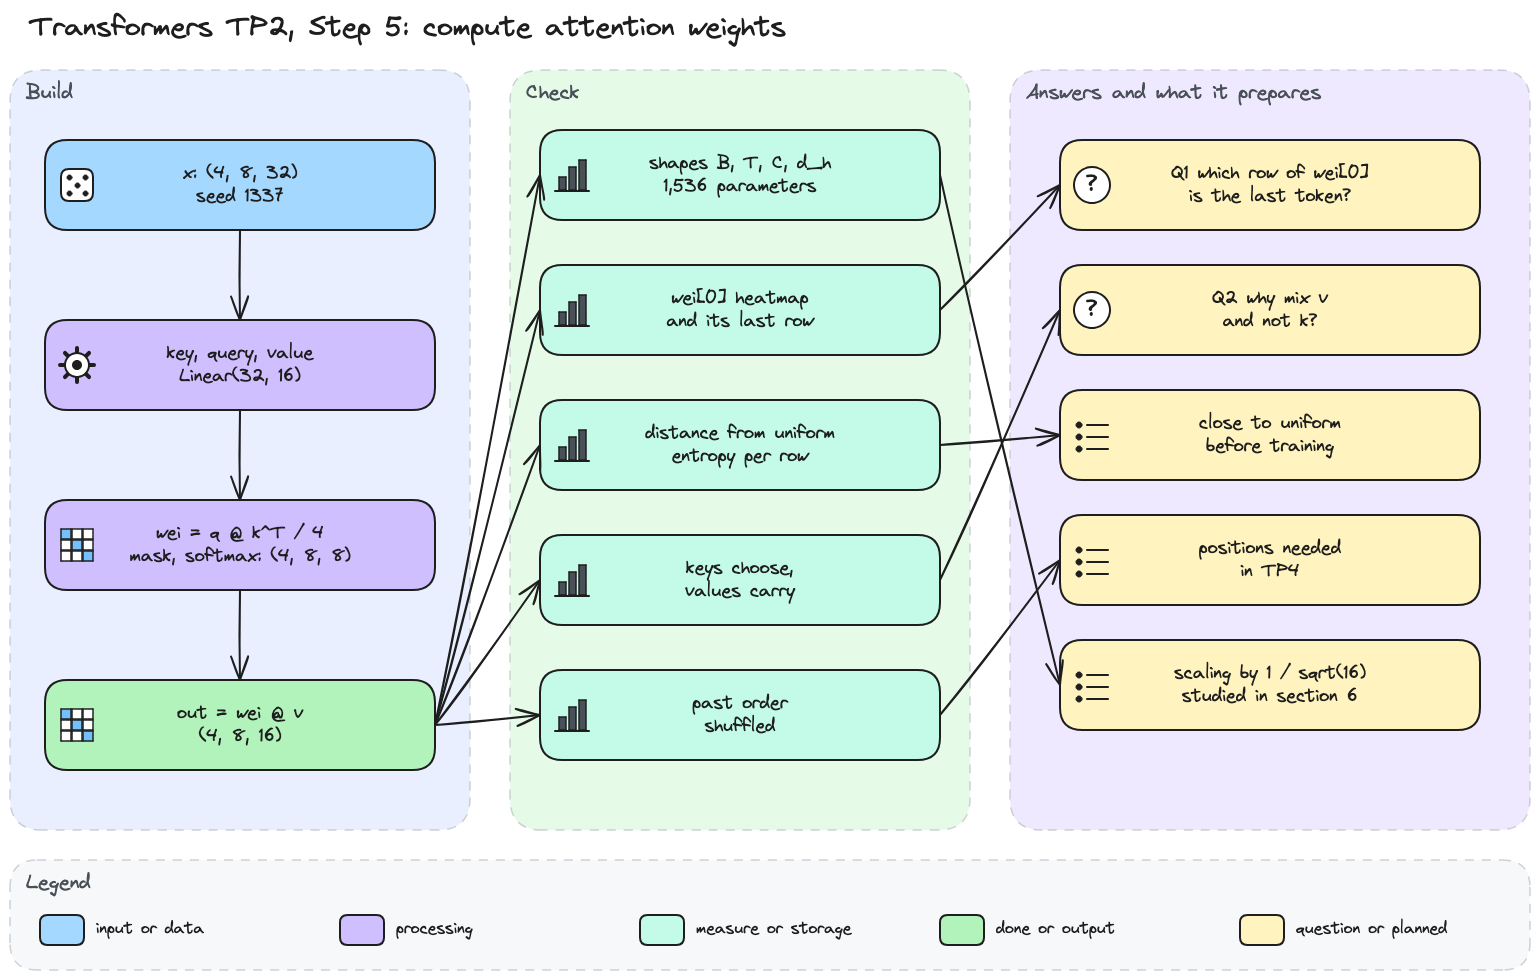

In [30]:
# Step 5 diagram: one attention head, its shapes, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step5.png', width=900))

In [31]:
# One attention head: keys, queries and values from x, then masked and normalised scores.
import torch.nn as nn

torch.manual_seed(1337)  # the TP2 seed, as in section 2
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
head_size = 16

key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)                      # (B,T,16)
q = query(x)                    # (B,T,16)
wei = q @ k.transpose(-2, -1)   # (B,T,T)
wei = wei * head_size**-0.5     # scaling, studied in section 6
wei = wei.masked_fill(tril[:T, :T] == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v                   # (B,T,16)

In [32]:
# Which shape means what? B sequences, T positions, C channels per token, d_h channels per head.
for name, tensor in (('x', x), ('k', k), ('q', q), ('k transposed', k.transpose(-2, -1)),
                     ('wei', wei), ('v', v), ('out', out)):
    print(f'{name}: {tuple(tensor.shape)}')

parameters = sum(p.numel() for layer in (key, query, value) for p in layer.parameters())
print(f'Parameters of key, query and value: {parameters:,}')
print(f'Rows of wei sum to 1: {torch.allclose(wei.sum(dim=-1), torch.ones(B, T))}, '
      f'nothing above the diagonal: {(wei.triu(1) == 0).all().item()}')

x: (4, 8, 32)
k: (4, 8, 16)
q: (4, 8, 16)
k transposed: (4, 16, 8)
wei: (4, 8, 8)
v: (4, 8, 16)
out: (4, 8, 16)
Parameters of key, query and value: 1,536
Rows of wei sum to 1: True, nothing above the diagonal: True


Each shape has a meaning. B = 4 sequences of T = 8 positions, and each token is a vector of C = 32 channels. The three layers project every token to d_h = 16 channels, so k, q and v all have shape (4, 8, 16). Transposing k to (4, 16, 8) lets `q @ kᵀ` give (4, 8, 8), one score for each pair of positions in each sequence. `out` comes back to (4, 8, 16), one mixed vector per position. The head has 3 × 32 × 16 = 1,536 parameters, and the invariant holds, with rows summing to 1 and nothing above the diagonal, as my hypothesis expected.

I look at the weights of the first sequence.

Last row, wei[0][7]: [0.084, 0.12, 0.108, 0.154, 0.109, 0.115, 0.156, 0.155]


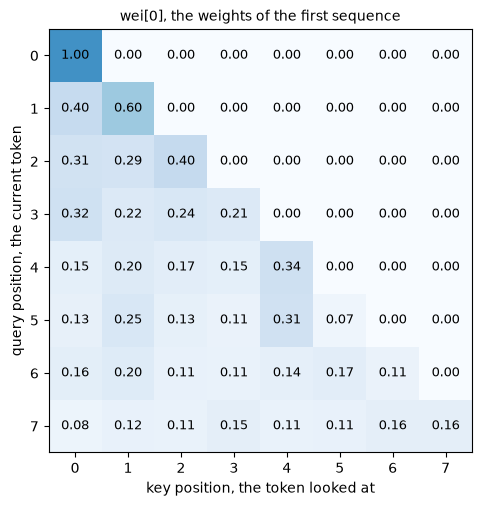

In [33]:
# The weights of the first sequence, wei[0]. Which row belongs to the last token?
print(f'Last row, wei[0][{T - 1}]: {[round(weight, 3) for weight in wei[0, -1].tolist()]}')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
show_matrix(ax, wei[0], 'wei[0], the weights of the first sequence')
ax.set_xlabel('key position, the token looked at')
ax.set_ylabel('query position, the current token')
plt.show()

Which row of `wei[0]` belongs to the last token? Row 7, the last row, at index T − 1, since row t holds the weights of the token at position t over the tokens it can see. It is the only row that sees all 8 tokens. Its weights go from 0.084 to 0.156, against 0.125 for a uniform row. Row 0 puts 1.00 on itself, the only token it may see. The other rows already differ from 1/(t+1), with 0.60 on token 1 in row 1 or 0.34 on token 4 in row 4.

I measure how far these rows are from the uniform weights of section 4.

Row 1: entropy 0.672, uniform ln(2) = 0.693
Row 4: entropy 1.552, uniform ln(5) = 1.609
Row 7: entropy 2.059, uniform ln(8) = 2.079


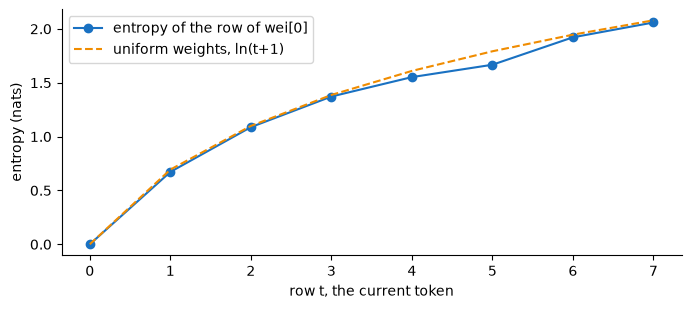

In [34]:
# How far from uniform are these weights? Entropy of each row against ln(t+1), the uniform case.
import math

weights0 = wei[0].detach()
entropy = -(weights0 * torch.log(weights0.clamp_min(1e-12))).sum(dim=1)  # 0 * log 0 counted as 0
for t in (1, 4, 7):
    print(f'Row {t}: entropy {entropy[t]:.3f}, uniform ln({t + 1}) = {math.log(t + 1):.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(T), entropy, marker='o', color='#1971c2', label='entropy of the row of wei[0]')
ax.plot(range(T), [math.log(t + 1) for t in range(T)], linestyle='--', color='#f08c00',
        label='uniform weights, ln(t+1)')
ax.set_xlabel('row t, the current token')
ax.set_ylabel('entropy (nats)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Entropy measures how spread a row is, as −Σ w ln w. It equals ln(t+1) when all the visible tokens weigh the same, and falls to 0 when one token takes everything. Every row sits just under the uniform curve, for example 2.059 against 2.079 in row 7 and 1.552 against 1.609 in row 4. So my hypothesis that the weights are no longer uniform is true, but only slightly before training. The keys and queries are random, so their scores barely differ, and training will have to sharpen them for a row to focus on the useful tokens.

The output mixes the values and not the keys, and I check why.

In [35]:
# Why mix v and not k? Compare key and value, then swap each layer for another random one.
cosine = F.cosine_similarity(k[0], v[0], dim=-1)
print(f'Cosine between key and value, token by token: {[round(c, 2) for c in cosine.tolist()]}')

torch.manual_seed(RANDOM_STATE)
other_key = nn.Linear(C, head_size, bias=False)
other_value = nn.Linear(C, head_size, bias=False)
other_scores = (q @ other_key(x).transpose(-2, -1)) * head_size**-0.5
other_wei = F.softmax(other_scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)
print(f'Another key layer: the weights move by up to {(other_wei - wei).abs().max().item():.3f}')
print(f'Another value layer: same weights, the output moves by up to '
      f'{(wei @ other_value(x) - out).abs().max().item():.2f}')

Cosine between key and value, token by token: [0.02, -0.08, -0.02, -0.1, 0.14, 0.57, 0.39, -0.1]
Another key layer: the weights move by up to 0.554
Another value layer: same weights, the output moves by up to 2.70


Why does the output mix v and not k directly? Changing the key layer moves the weights by up to 0.554, while changing the value layer leaves the weights untouched and moves the output by up to 2.70. So keys only decide where a token looks, and values only decide what it brings back. The key and the value of a token are different vectors, with cosines between −0.1 and 0.57. A token can then be found for one feature and hand over another. Mixing k would forbid that, since a token would have to pass on exactly what it is matched on.

Last, I check whether the head knows the order of the past.

In [36]:
# Does the head know the order? Shuffle the 7 past tokens of the first sequence, keep the last one.
torch.manual_seed(RANDOM_STATE)
order = torch.cat([torch.randperm(T - 1), torch.tensor([T - 1])])
shuffled = x[0, order].unsqueeze(0)
shuffled_scores = query(shuffled) @ key(shuffled).transpose(-2, -1) * head_size**-0.5
shuffled_wei = F.softmax(shuffled_scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)
shuffled_out = shuffled_wei @ value(shuffled)

print(f'New order of the tokens: {order.tolist()}')
print(f'Same output for the last token: '
      f'{torch.allclose(shuffled_out[0, -1], out[0, -1], atol=1e-6)}')

New order of the tokens: [1, 6, 3, 5, 4, 0, 2, 7]
Same output for the last token: True


After shuffling the 7 past tokens, the last token gets exactly the same output. The head sees its past as a set of tokens, as the average of section 1 did, so `First Ci` and its letters in another order would look the same to it. Order has to come from outside the head, which is what the position embeddings of TP4 will add.

> *My conclusion:*
>
> One head turns each token of (4, 8, 32) into a query, a key and a value of 16 channels. It scores every visible pair with q · kᵀ and mixes the values with the resulting weights. Rows still sum to 1 with nothing on the future, but before training the weights stay close to uniform, and the head ignores the order of the past. Section 6 looks at the scaling by 1/√16 that I used here without explaining it.
>
> My answers to the two questions of this step:
>
> 1. Row 7, the last row of `wei[0]` (index T − 1), belongs to the last token, and it is the only row that sees all 8 tokens.
> 2. The output mixes v because keys only decide where a token looks and values carry what it hands over. They are different vectors, so a token can be found for one feature and pass on another.

## 6. Stabilise softmax

In section 5 I divided the scores by √16 without checking why. A dot product adds up d_h products, so its spread should grow with the head size, and I want to see what that does to softmax. The diagram shows the check and the experiments around it.

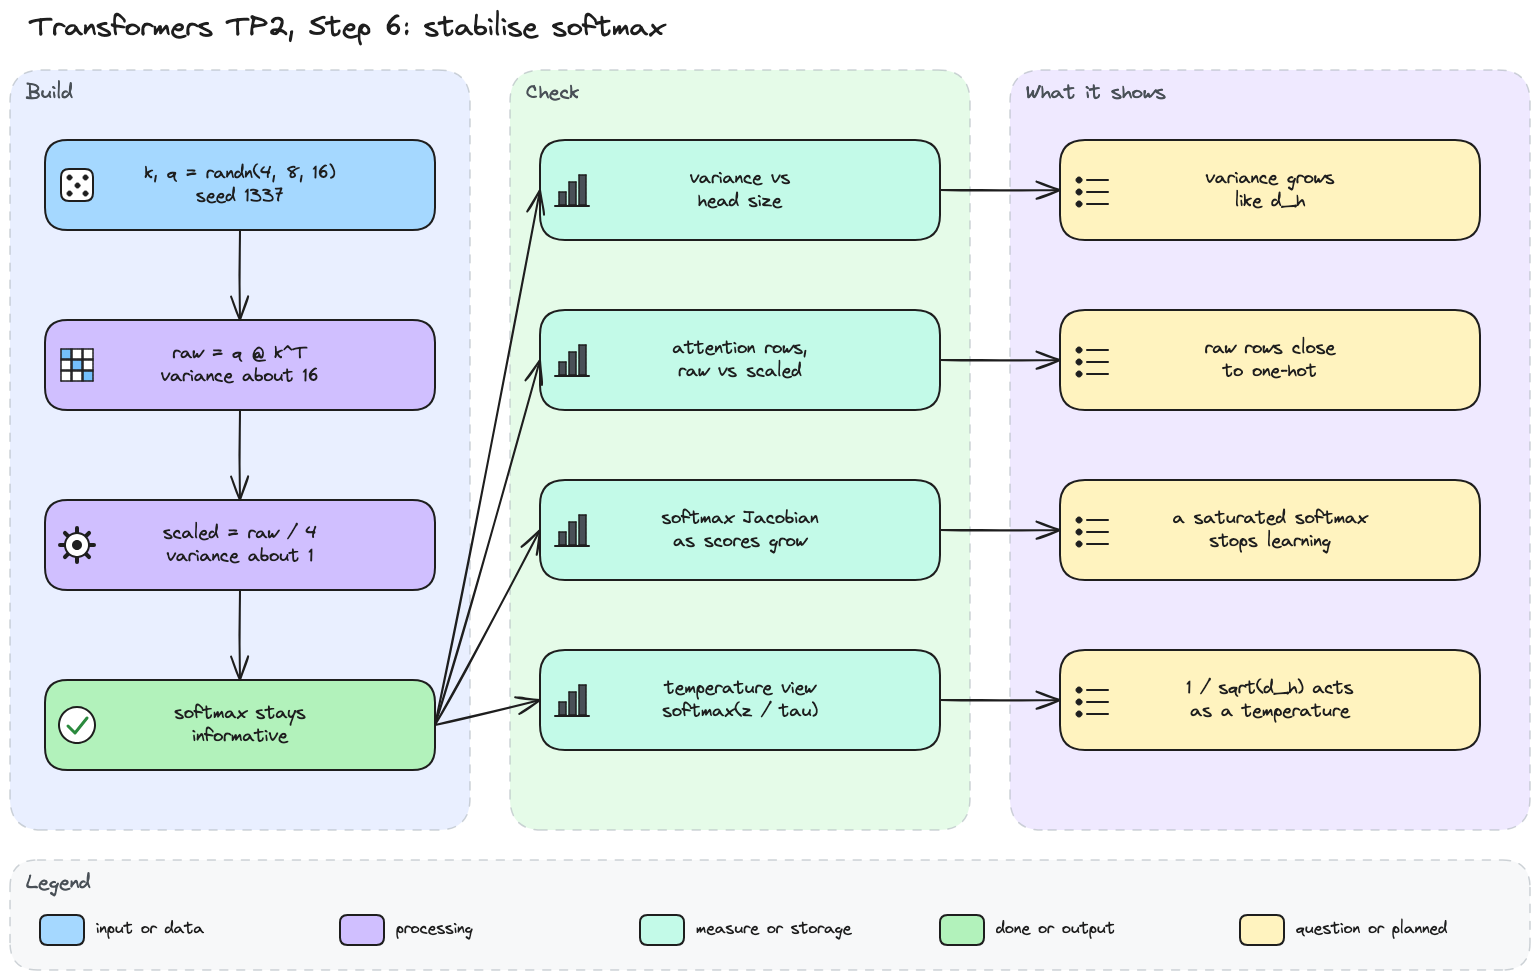

In [37]:
# Step 6 diagram: raw and scaled scores, and the experiments behind my conclusion.
display(Image(filename='diagrams/transformers/tp2_step6.png', width=900))

In [38]:
# Why divide by sqrt(head_size)? The variance of raw and scaled scores for random keys and queries.
torch.manual_seed(1337)
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)

raw = q @ k.transpose(-2, -1)
scaled = raw * head_size**-0.5

print(raw.var(), scaled.var())

tensor(18.4436) tensor(1.1527)


The raw scores have a variance of 18.44 and the scaled ones 1.15. Each raw score adds 16 products of two independent numbers of variance 1, so I expect a variance close to 16. Dividing by √16 = 4 divides the variance by 16, and 18.44 / 16 gives the 1.15 I see. The sample holds only 4 × 8 × 8 = 256 scores, so I read these values as noisy estimates of 16 and 1.

A variance of 16 means raw scores spread over several units. I want to see what such a spread does to softmax.

In [39]:
# What does a larger spread do to softmax? The same five scores, then multiplied by 8.
z = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
print(torch.softmax(z, dim=-1))
print(torch.softmax(z * 8, dim=-1))

tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


With the five scores as they are, softmax keeps every weight between 0.143 and 0.287, so each score gets a share. Multiplied by 8, the scores keep the same order, yet the largest one takes 0.800 and the two smallest only 0.003. A wider spread pushes softmax toward one winner, which is my hypothesis seen on a single row.

Before testing it on attention rows, I check whether the raw variance really follows the head size beyond d_h = 16.

d_h = 4: raw variance 4.08, scaled variance 1.021
d_h = 16: raw variance 16.14, scaled variance 1.009
d_h = 64: raw variance 64.57, scaled variance 1.009
d_h = 256: raw variance 254.57, scaled variance 0.994


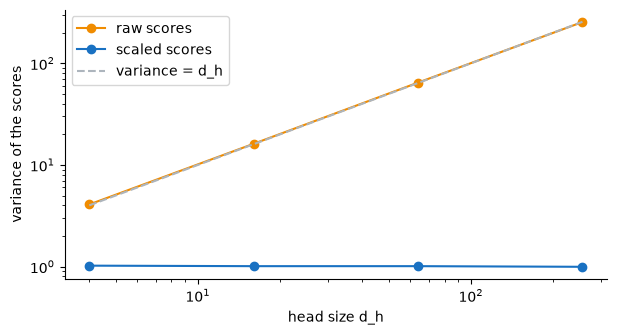

In [40]:
# Does the raw variance follow the head size? Raw and scaled variances for several d_h.
torch.manual_seed(RANDOM_STATE)
HEAD_SIZES = [4, 16, 64, 256]
samples = {}
for d in HEAD_SIZES:
    samples[d] = torch.randn(1000, T, d) @ torch.randn(1000, T, d).transpose(-2, -1)
    print(f'd_h = {d}: raw variance {samples[d].var():.2f}, '
          f'scaled variance {(samples[d] * d**-0.5).var():.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(HEAD_SIZES, [samples[d].var() for d in HEAD_SIZES], marker='o', color='#f08c00',
        label='raw scores')
ax.plot(HEAD_SIZES, [(samples[d] * d**-0.5).var() for d in HEAD_SIZES], marker='o',
        color='#1971c2', label='scaled scores')
ax.plot(HEAD_SIZES, HEAD_SIZES, linestyle='--', color='#adb5bd', label='variance = d_h')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('head size d_h')
ax.set_ylabel('variance of the scores')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The raw variance follows the head size, from 4.08 at d_h = 4 to 254.57 at d_h = 256. Its line sits on the dashed line variance = d_h. The scaled variance stays between 0.994 and 1.021. So √d_h is the right divisor whatever the head size, and a bigger head would make raw scores worse.

Now I want to see what this growing spread does to the attention rows themselves.

d_h = 4: largest weight raw 0.54, scaled 0.35, entropy raw 1.27, scaled 1.74
d_h = 16: largest weight raw 0.75, scaled 0.36, entropy raw 0.67, scaled 1.72
d_h = 64: largest weight raw 0.87, scaled 0.36, entropy raw 0.32, scaled 1.72
d_h = 256: largest weight raw 0.94, scaled 0.36, entropy raw 0.14, scaled 1.73
Entropy of a uniform last row, ln(8): 2.08


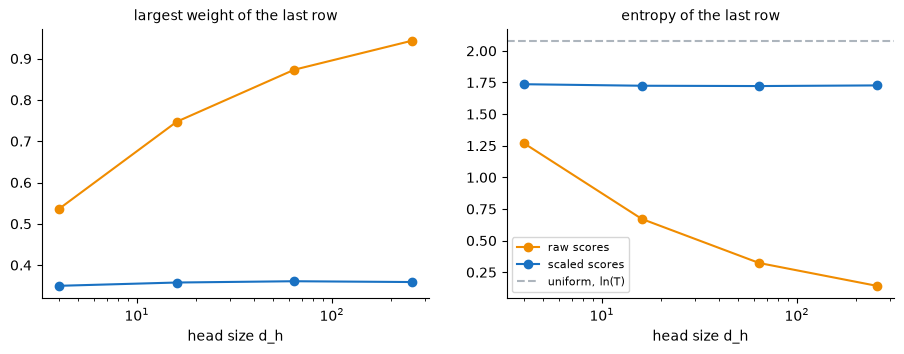

In [41]:
# What does each version do to the attention rows? Masked softmax of raw and scaled scores.
largest = {'raw': [], 'scaled': []}
spread = {'raw': [], 'scaled': []}
for d in HEAD_SIZES:
    for name, scores in (('raw', samples[d]), ('scaled', samples[d] * d**-0.5)):
        rows = F.softmax(scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)[:, -1]
        largest[name].append(rows.max(dim=-1).values.mean().item())
        spread[name].append(-(rows * torch.log(rows.clamp_min(1e-12))).sum(dim=-1).mean().item())
    print(f'd_h = {d}: largest weight raw {largest["raw"][-1]:.2f}, '
          f'scaled {largest["scaled"][-1]:.2f}, '
          f'entropy raw {spread["raw"][-1]:.2f}, scaled {spread["scaled"][-1]:.2f}')
print(f'Entropy of a uniform last row, ln({T}): {math.log(T):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, values, title in ((axes[0], largest, 'largest weight of the last row'),
                          (axes[1], spread, 'entropy of the last row')):
    ax.plot(HEAD_SIZES, values['raw'], marker='o', color='#f08c00', label='raw scores')
    ax.plot(HEAD_SIZES, values['scaled'], marker='o', color='#1971c2', label='scaled scores')
    ax.set_xscale('log')
    ax.set_xlabel('head size d_h')
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].axhline(math.log(T), linestyle='--', color='#adb5bd', label='uniform, ln(T)')
axes[1].legend(fontsize=8)
plt.show()

I look at the last row, the only one that sees all 8 tokens. Its entropy measures how spread the weights are, ln(8) = 2.08 for a uniform row and 0 when one token takes everything.

With raw scores, the largest weight grows from 0.54 at d_h = 4 to 0.94 at d_h = 256, and the entropy falls from 1.27 to 0.14. With scaled scores, the largest weight stays between 0.35 and 0.36 and the entropy between 1.72 and 1.74 at every size. At d_h = 16, the size of my head in section 5, the raw row already gives 0.75 to one token.

My hypothesis holds, and the effect grows with the head size. A row this sharp makes me wonder whether training can still move it, so I look at the gradient next.

scale 0.25: largest weight 0.221, Jacobian norm 0.4002
scale 1: largest weight 0.287, Jacobian norm 0.4033
scale 2: largest weight 0.383, Jacobian norm 0.4095
scale 4: largest weight 0.564, Jacobian norm 0.4016
scale 8: largest weight 0.800, Jacobian norm 0.2825
scale 16: largest weight 0.959, Jacobian norm 0.0759
scale 32: largest weight 0.998, Jacobian norm 0.0033


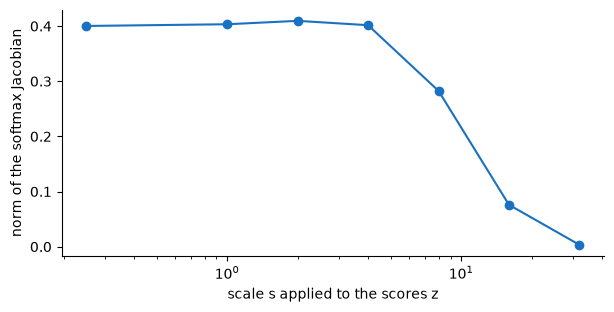

In [42]:
# Can a saturated softmax still learn? The size of its Jacobian diag(p) - p p^T as scores grow.
SCALES = [0.25, 1, 2, 4, 8, 16, 32]
jacobian_norms = []
for s in SCALES:
    p = torch.softmax(z * s, dim=-1)
    jacobian_norms.append(torch.linalg.matrix_norm(torch.diag(p) - torch.outer(p, p)).item())
    print(f'scale {s}: largest weight {p.max():.3f}, Jacobian norm {jacobian_norms[-1]:.4f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(SCALES, jacobian_norms, marker='o', color='#1971c2')
ax.set_xscale('log')
ax.set_xlabel('scale s applied to the scores z')
ax.set_ylabel('norm of the softmax Jacobian')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The Jacobian of softmax, diag(p) − p pᵀ, tells how much each weight moves when one score moves. Every gradient that trains the queries and keys passes through it, so its size tells me whether a row can still learn.

Up to a scale of 4 its norm stays near 0.40, while the largest weight rises from 0.221 to 0.564. Then it collapses, to 0.2825 at scale 8, 0.0759 at 16 and 0.0033 at 32, where the largest weight is 0.998.

A nearly one-hot row hardly reacts to its scores, so the gradient fades before it reaches q and k. Without the division, the scores of a head are √d_h times larger, which pushes a large head toward the right of this curve.

temperature 4.0: [0.2, 0.185, 0.21, 0.185, 0.221]
temperature 1.0: [0.192, 0.143, 0.235, 0.143, 0.287]
temperature 0.25: [0.114, 0.034, 0.253, 0.034, 0.564]
temperature 0.125: [0.033, 0.003, 0.162, 0.003, 0.8]


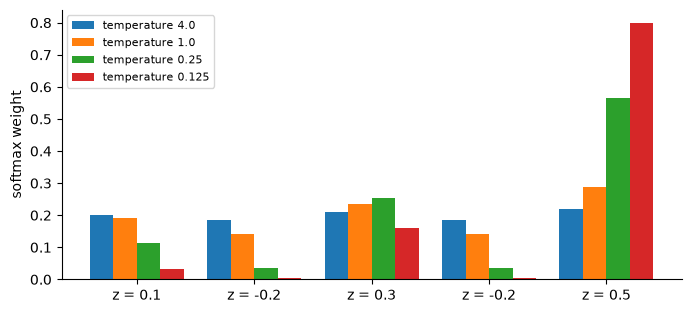

In [43]:
# Dividing by sqrt(d_h) as a temperature: softmax of z divided by several temperatures.
TEMPERATURES = [4.0, 1.0, 0.25, 0.125]  # z * 8 of the handout is a temperature of 1/8
positions = torch.arange(len(z))
fig, ax = plt.subplots(figsize=(8, 3.5))
for k_index, tau in enumerate(TEMPERATURES):
    weights_tau = torch.softmax(z / tau, dim=-1)
    print(f'temperature {tau}: {[round(w, 3) for w in weights_tau.tolist()]}')
    ax.bar(positions + 0.2 * (k_index - 1.5), weights_tau, 0.2, label=f'temperature {tau}')
ax.set_xticks(positions, [f'z = {score:.1f}' for score in z.tolist()])
ax.set_ylabel('softmax weight')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Dividing the scores by a temperature changes how sharp softmax is. At a temperature of 4 the five weights stay between 0.185 and 0.221, close to uniform. At 0.125, which is the z × 8 of the earlier cell, the largest score takes 0.8. A low temperature tends to argmax and a high one to a uniform row.

I met the same knob in TP1 transformers, section 6, where greedy decoding, the zero temperature limit, looped on a cycle of 9 characters. In my NLP TP3 I chose temperature 0 on purpose, to get a repeatable answer.

Dividing by √d_h sets attention at a temperature where every visible token keeps some weight, whatever the head size.

> *My conclusion:*
>
> Raw scores q · kᵀ have a variance close to d_h, from 4.08 at d_h = 4 to 254.57 at d_h = 256, while scaled scores stay near 1. Without the division, the last attention row of my 16-channel head already gives 0.75 to one token, and 0.94 at d_h = 256. My hypothesis on scaling holds, and the effect grows with the head size.
>
> A row that saturated also stops passing gradient, since the norm of the softmax Jacobian falls from about 0.40 to 0.0033 as the scores grow 32 times. Dividing by √d_h works as a fixed temperature that keeps every head size in the range where attention can learn. The summary gathers the invariants of every version and the roles of Q, K and V.

## Summary

I go back to my four hypotheses and give each one a verdict from what I measured. Then I check the invariant one last time on the four versions at once, on the same input `x`.

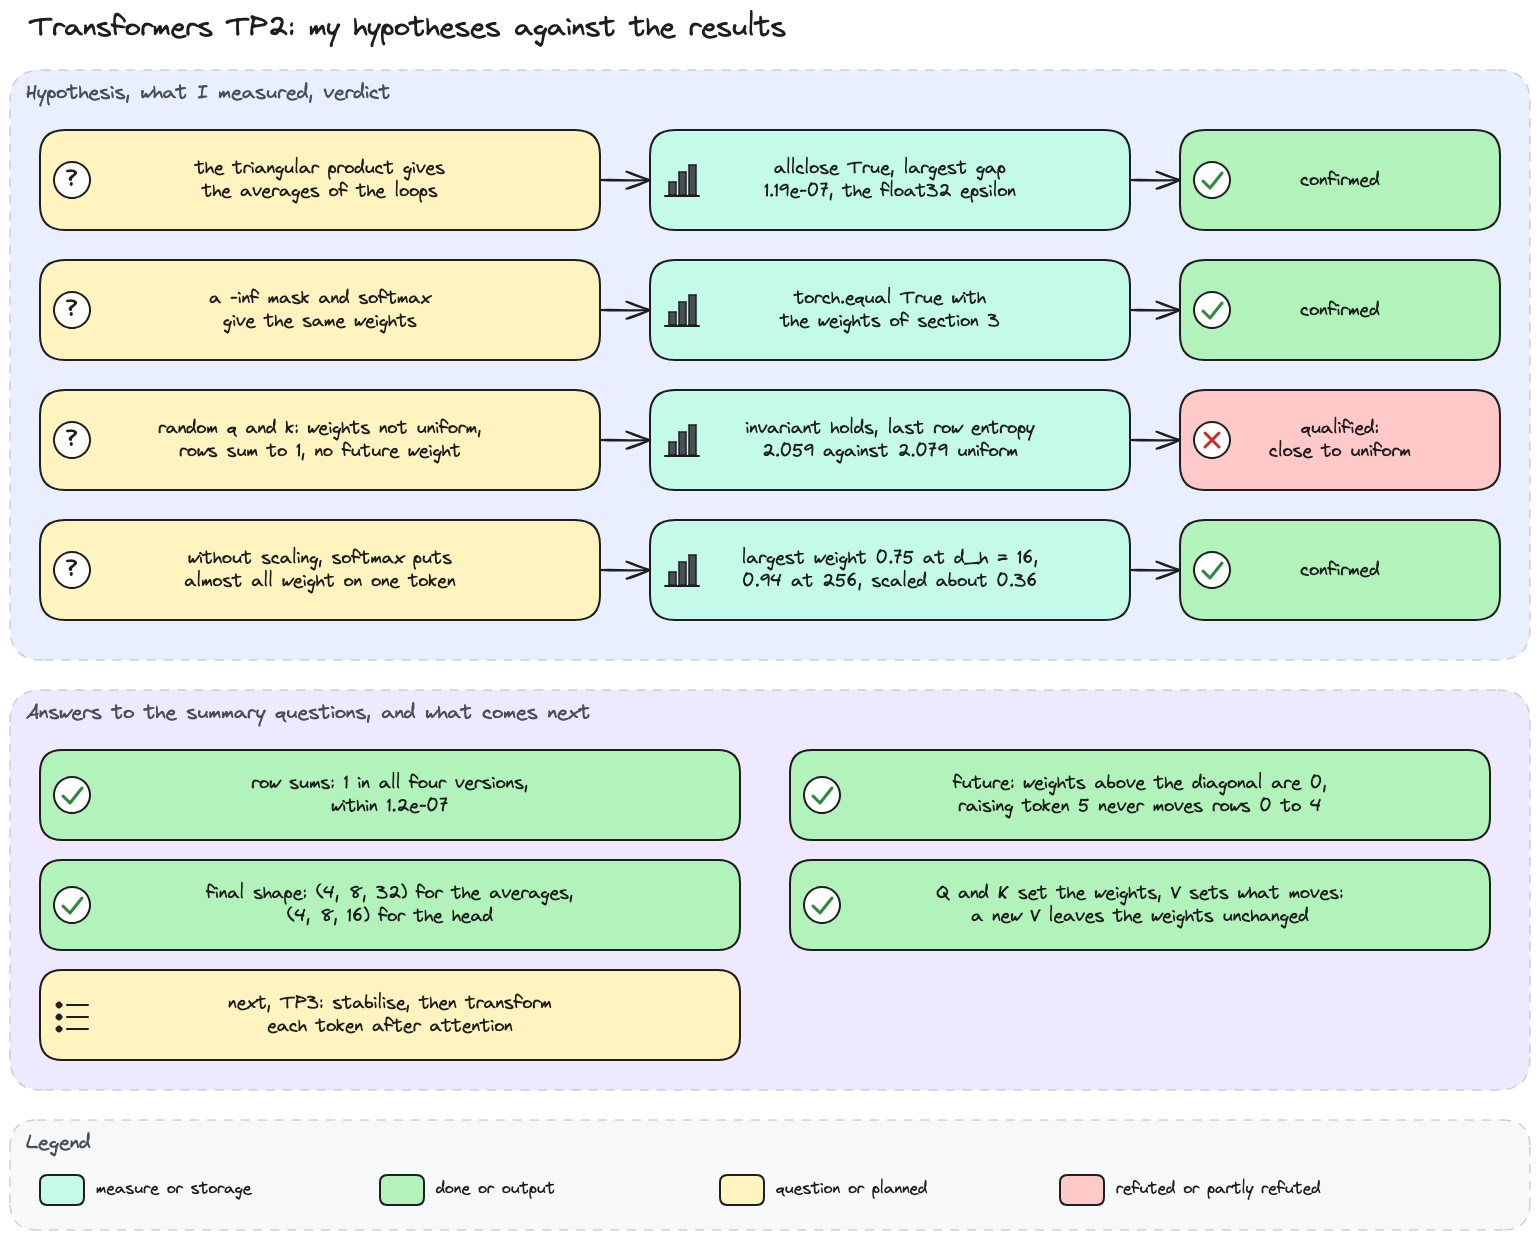

In [44]:
# Summary diagram: my hypotheses, what I measured, my verdicts, and the summary answers.
display(Image(filename='diagrams/transformers/tp2_summary.png', width=900))

In [45]:
# Tools: the four versions as functions of x, each returning its output and its weights.
def head_mix(x: torch.Tensor, q: nn.Module = query, k: nn.Module = key,
             v: nn.Module = value) -> tuple[torch.Tensor, torch.Tensor]:
    """The head of section 5: masked softmax of the scaled q · kᵀ, then a mix of the values."""
    scores = q(x) @ k(x).transpose(-2, -1) * head_size**-0.5
    wei = F.softmax(scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)
    return wei @ v(x), wei


# The weights of section 4, rebuilt because section 5 reused the name wei
uniform = F.softmax(torch.zeros(T, T).masked_fill(tril == 0, float('-inf')), dim=-1)

VERSIONS = {
    # the loops applied to the identity reveal the weights they use
    'two loops': lambda x: (loop_mean(x), loop_mean(torch.eye(T).expand(len(x), T, T))),
    'triangular product': lambda x: (weights @ x, weights.expand(len(x), T, T)),
    'mask and softmax': lambda x: (uniform @ x, uniform.expand(len(x), T, T)),
    'attention head': head_mix,
}

In [46]:
# Do the four versions keep the invariant? Row sums, future weights and final shape on x.
print(f'x: {tuple(x.shape)}')
for name, version in VERSIONS.items():
    output, version_weights = version(x)
    gap = (version_weights.sum(dim=-1) - 1).abs().max().item()
    future = version_weights.triu(1).abs().max().item()
    print(f'{name}: output {tuple(output.shape)}, row sums within {gap:.1e} of 1, '
          f'largest future weight {future}')

x: (4, 8, 32)
two loops: output (4, 8, 32), row sums within 1.2e-07 of 1, largest future weight 0.0
triangular product: output (4, 8, 32), row sums within 1.2e-07 of 1, largest future weight 0.0
mask and softmax: output (4, 8, 32), row sums within 1.2e-07 of 1, largest future weight 0.0
attention head: output (4, 8, 16), row sums within 1.2e-07 of 1, largest future weight 0.0


All four versions keep the invariant on the same `x`. Every row sums to 1 within 1.2e-07, the float32 rounding, and the largest weight above the diagonal is 0.0. The three averages keep the shape (4, 8, 32) of `x`, while the head returns (4, 8, 16) because it mixes values of d_h = 16 channels.

A zero weight should mean that the future cannot leak into a row. I want to see it on the outputs too.

two loops: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 1.67, 1.43, 1.25]
triangular product: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 1.67, 1.43, 1.25]
mask and softmax: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 1.67, 1.43, 1.25]
attention head: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 0.26, 0.51, 0.48]


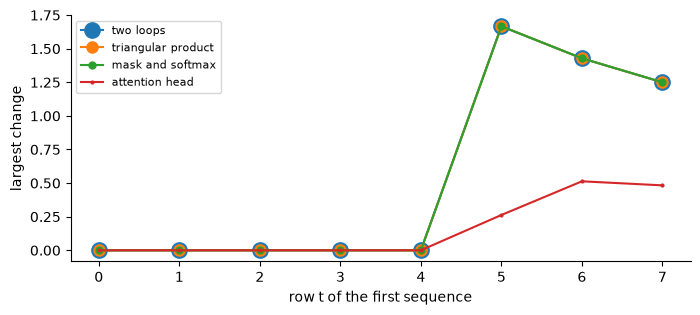

In [47]:
# Does any version read the future? Token 5 of the first sequence raised by 10, then rerun.
changed = x.clone()
changed[0, 5] += 10
moves = {}
for name, version in VERSIONS.items():
    moves[name] = (version(changed)[0][0] - version(x)[0][0]).abs().max(dim=1).values.detach()
    print(f'{name}: largest change per row {[round(v, 2) for v in moves[name].tolist()]}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for index, (name, move) in enumerate(moves.items()):
    ax.plot(range(T), move, marker='o', markersize=11 - 3 * index, label=name)  # visible overlaps
ax.set_xlabel('row t of the first sequence')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Raising token 5 by 10 never moves rows 0 to 4, in any version, so no row reads the future. The three averages move rows 5 to 7 by 1.67, 1.43 and 1.25, which are 10/6, 10/7 and 10/8.

The head moves the same rows by 0.26, 0.51 and 0.48, so its effect does not shrink with t. Its weights depend on the tokens, so a changed token also changes how much the others look at it. I want to compare the weights themselves.

Weights read from the loops equal the weights of section 1: True
two loops, last row: [0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125]
triangular product, last row: [0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125]
mask and softmax, last row: [0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125]
attention head, last row: [0.084, 0.12, 0.108, 0.154, 0.109, 0.115, 0.156, 0.155]


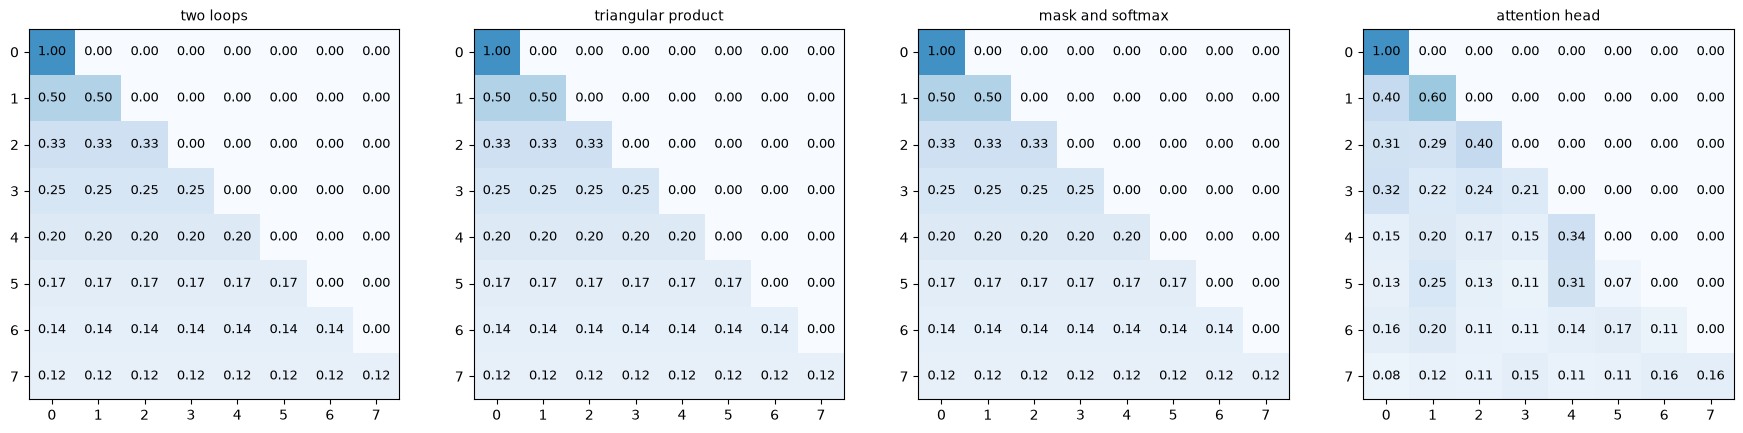

In [48]:
# The weights of the first sequence in each version, side by side. The last panel is wei[0].
loop_weights = VERSIONS['two loops'](x)[1][0]
print(f'Weights read from the loops equal the weights of section 1: '
      f'{torch.equal(loop_weights, weights)}')

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (name, version) in zip(axes, VERSIONS.items()):
    last = version(x)[1][0]
    print(f'{name}, last row: {[round(w, 3) for w in last[-1].tolist()]}')
    show_matrix(ax, last, name)
plt.show()

Feeding the identity through the loops gives exactly the weights of section 1, so the loops used the same matrix all along. The first three panels are identical, with 1/(t+1) on every visible token and 0.125 everywhere in the last row.

The head keeps the same triangle, but its last row goes from 0.084 to 0.156, and row 5 gives token 5 only 0.07. These uneven weights come from q and k, so I end by checking what each of the three layers controls.

Another query layer: weights move by up to 0.255, output by up to 0.56
Another key layer: weights move by up to 0.554, output by up to 1.07
Another value layer: weights move by up to 0.000, output by up to 2.70


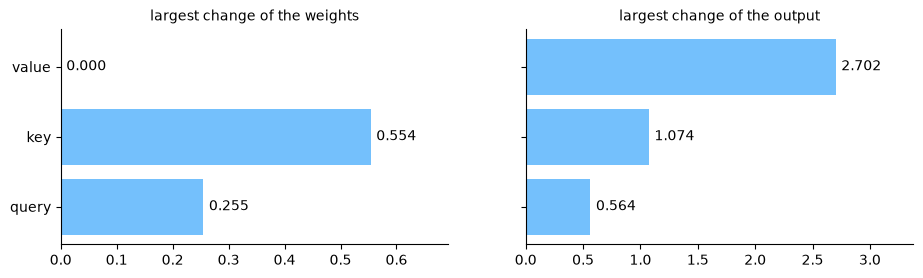

In [49]:
# Which layer sets what? Swap query, key or value for another random layer, one at a time.
torch.manual_seed(RANDOM_STATE)
# created in this order so the key and value layers are those of section 5
other_key, other_value, other_query = (nn.Linear(C, head_size, bias=False) for _ in range(3))
swaps = {'query': {'q': other_query}, 'key': {'k': other_key}, 'value': {'v': other_value}}
weight_moves, output_moves = [], []
for name, swap in swaps.items():
    swapped_out, swapped_wei = head_mix(x, **swap)
    weight_moves.append((swapped_wei - wei).abs().max().item())
    output_moves.append((swapped_out - out).abs().max().item())
    print(f'Another {name} layer: weights move by up to {weight_moves[-1]:.3f}, '
          f'output by up to {output_moves[-1]:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
for ax, values, title in ((axes[0], weight_moves, 'largest change of the weights'),
                          (axes[1], output_moves, 'largest change of the output')):
    bars = ax.barh(list(swaps), values, color='#74c0fc')
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=4)
    ax.set_xlim(0, max(values) * 1.25)
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

Another query layer moves the weights by up to 0.255, and another key layer by up to 0.554. Another value layer moves them by 0.000, yet it changes the output by up to 2.70, the largest change of the three.

So the query of a token and the keys of the others decide the weights, and the values decide what those weights carry. The query is what a token looks for, the key is what each token offers, and the value is what it hands over once chosen.

> *My conclusion:*
>
> I went from two loops to one attention head, and every version keeps the same invariant. Each row of weights sums to 1 and gives nothing to the future. My hypotheses now have these verdicts.
>
> - The triangular product gives the averages of the loops, with a largest gap of 1.19e-07, the float32 epsilon. Confirmed.
> - A −∞ mask followed by softmax gives exactly the weights of section 3. Confirmed.
> - Random keys and queries keep the invariant and give uneven weights. The last row of `wei[0]` still stays close to uniform, with an entropy of 2.059 against 2.079, so this hypothesis holds only weakly before training.
> - Without scaling, the variance of q · kᵀ follows d_h, and the last row gives 0.75 to one token at d_h = 16. Confirmed, and stronger as d_h grows.
>
> Attention keeps the frame of the causal average, the triangle and the rows summing to 1. It only replaces the fixed 1/(t+1) by weights computed from the tokens, and the scaling by 1/√d_h keeps these weights trainable.
>
> My answers to the four summary questions of TP2:
>
> 1. The rows of the weights sum to 1 within 1.2e-07 in all four versions.
> 2. Every weight above the diagonal is 0.0, and raising token 5 never moves rows 0 to 4.
> 3. The averages return (4, 8, 32) like `x`, and the head returns (B, T, d_h) = (4, 8, 16).
> 4. Q holds what a token looks for and K what each token offers, so together they set the weights. V carries what is handed over, since a new value layer leaves the weights unchanged and moves the output by 2.70.
>
> These checks use one seed and an untrained head that ignores the order of the tokens. TP3 will stabilise the head and then transform each token after attention.